## Table of Contents
* [1. Data Loading & Basic Checks](#1-data-loading--basic-checks)
  * [Table Previews](#table-previews)
* [2. Missing Values & Time-Series Cleaning](#2-missing-values--time-series-cleaning)
  * [2.1 Checking Calendar Completeness & Inserting Missing Christmas Dates](#21-checking-calendar-completeness--inserting-missing-christmas-dates)
  * [2.2 Filling Non-Holiday Dates (`holiday_name`)](#22-filling-non-holiday-dates-holiday_name)
  * [2.3 Imputing Missing Oil Prices (`oil_price`)](#23-imputing-missing-oil-prices-oil_price)
  * [2.4 Final Missing Values Check](#24-final-missing-values-check)
* [3. Exploratory Data Analysis (EDA) & Domain Insights](#3-exploratory-data-analysis-eda--domain-insights)
  * [3.1 Total Daily Sales over Time (Daily vs. 7-Day Trend)](#31-total-daily-sales-over-time-daily-vs-7-day-trend)
  * [3.2 Product Family & Store Scale](#32-product-family--store-scale)
  * [3.3 Average Sales per Day of Month (Payday Effect)](#33-average-sales-per-day-of-month-payday-effect)
  * [3.4 Average Sales per Weekday (Weekend Effect)](#34-average-sales-per-weekday-weekend-effect)
  * [3.5 Oil Price vs. Sales](#35-oil-price-vs-sales)
  * [3.6 Promotions vs. Sales](#36-promotions-vs-sales)
  * [3.7 Store Transactions vs. Sales](#37-store-transactions-vs-sales)
  * [3.8 Target Distribution (RMSLE) & Lagged Sales Autocorrelation](#38-target-distribution-rmsle--lagged-sales-autocorrelation)
* [4. Feature Engineering Pipeline](#4-feature-engineering-pipeline)
  * [4.1 Exporting Processed Feature Matrices](#41-exporting-processed-feature-matrices)

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import db_dtypes
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import Markdown, display
import gc

pd.set_option('display.max_columns', None)

# Dynamically resolve the data directory regardless of the active working directory
cwd = Path.cwd()
if (cwd / "data").exists():
    DATA_DIR = cwd / "data"
elif (cwd.parent / "data").exists():
    DATA_DIR = cwd.parent / "data"
else:
    DATA_DIR = cwd / "store-sales-forecasting" / "data"

print(f"Active Data Directory: {DATA_DIR.resolve()}")

Active Data Directory: /home/user/myprojects/store-sales-forecasting/data


# 1. Data Loading & Basic Checks
Load the extracted Parquet tables from `data/interim/`, convert the `date` column to standard pandas datetime, and sort the rows chronologically. Since BigQuery exports data from distributed workers, sorting by `(store_nbr, family, date)` is essential before running any time-series operations.

In [2]:
df_train = pd.read_parquet(DATA_DIR / 'interim/train.parquet')
df_test = pd.read_parquet(DATA_DIR / 'interim/test.parquet')
df_transactions = pd.read_parquet(DATA_DIR / 'interim/transactions.parquet')

for df in [df_train, df_test, df_transactions]:
    df['date'] = pd.to_datetime(df['date'])

df_train = df_train.sort_values(by=['store_nbr', 'family', 'date']).reset_index(drop=True)
df_test = df_test.sort_values(by=['store_nbr', 'family', 'date']).reset_index(drop=True)
df_transactions = df_transactions.sort_values(by=['store_nbr', 'date']).reset_index(drop=True)

print('TRAIN.PARQUET DTYPES:', df_train.dtypes, sep='\n', end='\n\n')
display(Markdown('---'))
print('TEST.PARQUET DTYPES:', df_test.dtypes, sep='\n', end='\n\n')
display(Markdown('---'))
print('TRANSACTIONS.PARQUET DTYPES:', df_transactions.dtypes, sep='\n', end='\n\n')

TRAIN.PARQUET DTYPES:
id                      Int64
date            datetime64[s]
store_nbr               Int64
family                    str
onpromotion             Int64
city                      str
state                     str
store_type                str
cluster                 Int64
oil_price             float64
sales                 float64
is_holiday            boolean
holiday_name              str
dtype: object



---

TEST.PARQUET DTYPES:
id                      Int64
date            datetime64[s]
store_nbr               Int64
family                    str
onpromotion             Int64
city                      str
state                     str
store_type                str
cluster                 Int64
oil_price             float64
is_holiday            boolean
holiday_name              str
dtype: object



---

TRANSACTIONS.PARQUET DTYPES:
date            datetime64[s]
store_nbr               Int64
transactions            Int64
dtype: object



### Table Previews
Inspect each table to confirm the date ranges and sorting order.

In [3]:
print('TRAIN.PARQUET PREVIEW:')
display(df_train)
display(Markdown('---'))
print('TEST.PARQUET PREVIEW:')
display(df_test)
display(Markdown('---'))
print('TRANSACTIONS.PARQUET PREVIEW:')
display(df_transactions)

TRAIN.PARQUET PREVIEW:


,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,sales,is_holiday,holiday_name
0,0,2013-01-01,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,0.0,True,Primer dia del ano
1,1782,2013-01-02,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,93.14,2.0,False,NaN
2,3564,2013-01-03,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,92.97,3.0,False,NaN
3,5346,2013-01-04,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,93.12,3.0,False,NaN
4,7128,2013-01-05,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,5.0,False,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3000883,2993627,2017-08-11,54,SEAFOOD,0,El Carmen,Manabi,C,3,48.81,0.0,True,Traslado Primer Grito de Independencia
3000884,2995409,2017-08-12,54,SEAFOOD,1,El Carmen,Manabi,C,3,NaN,1.0,False,NaN
3000885,2997191,2017-08-13,54,SEAFOOD,0,El Carmen,Manabi,C,3,NaN,2.0,False,NaN
3000886,2998973,2017-08-14,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.59,0.0,False,NaN


---

TEST.PARQUET PREVIEW:


,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,is_holiday,holiday_name
0,3000888,2017-08-16,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,46.80,False,NaN
1,3002670,2017-08-17,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,47.07,False,NaN
2,3004452,2017-08-18,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,48.59,False,NaN
3,3006234,2017-08-19,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,False,NaN
4,3008016,2017-08-20,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,False,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
28507,3022139,2017-08-27,54,SEAFOOD,0,El Carmen,Manabi,C,3,NaN,False,NaN
28508,3023921,2017-08-28,54,SEAFOOD,0,El Carmen,Manabi,C,3,46.40,False,NaN
28509,3025703,2017-08-29,54,SEAFOOD,0,El Carmen,Manabi,C,3,46.46,False,NaN
28510,3027485,2017-08-30,54,SEAFOOD,0,El Carmen,Manabi,C,3,45.96,False,NaN


---

TRANSACTIONS.PARQUET PREVIEW:


,date,store_nbr,transactions
0,2013-01-02,1,2111
1,2013-01-03,1,1833
2,2013-01-04,1,1863
3,2013-01-05,1,1509
4,2013-01-06,1,520
...,...,...,...
83483,2017-08-11,54,768
83484,2017-08-12,54,903
83485,2017-08-13,54,1054
83486,2017-08-14,54,818


# 2. Missing Values & Time-Series Cleaning
Before building features, we need to ensure our calendar timeline has no missing dates and handle missing values in `holiday_name` and `oil_price` so the dataset is complete and ready for modeling.

In [4]:
def print_perc_of_nans(df, col_names, name="DF"):
    for col_name in col_names:
        nans = df[col_name].isna().sum()
        total = len(df)
        perc = (nans * 100.0) / total
        print(f'{name} - {col_name}: {nans:,} NaNs out of {total:,} ({perc:.1f}%)', end='\n')

### 2.1 Checking Calendar Completeness & Inserting Missing Christmas Dates
A complete daily timeline from `2013-01-01` to `2017-08-15` spans **1,688 calendar days**. Across 54 stores and 33 product families ($54 \times 33 = 1,782$ series), `df_train` should contain $1,688 \times 1,782 = 3,008,016$ rows, but it only has $3,000,888$ rows: a deficit of **7,128 rows** (exactly 4 full days).

Below, we verify that all 54 stores and 33 families are present on every recorded date, identify the 4 missing dates (Christmas Day, Dec 25, for 2013–2016 when stores were closed), and insert them with `sales = 0`. Filling these calendar gaps ensures that row-based time-series shifts (such as `.shift(21)`) align with date-based time-series shifts.

In [5]:
# Expected vs. actual dimensions
full_train_calendar = pd.date_range(start='2013-01-01', end='2017-08-15', freq='D')
n_expected_days = len(full_train_calendar)
n_stores = df_train['store_nbr'].nunique()
n_families = df_train['family'].nunique()
expected_rows = n_expected_days * n_stores * n_families
missing_rows = expected_rows - len(df_train)

print(f"Expected calendar days (2013-01-01 to 2017-08-15): {n_expected_days}")
print(f"Unique stores: {n_stores} | Unique families: {n_families} (Series per day: {n_stores * n_families})")
print(f"Expected rows: {expected_rows:,} | Actual rows: {len(df_train):,}")
print(f"Missing rows:  {missing_rows:,} ({missing_rows // (n_stores * n_families)} full days)\n")

# Check if any recorded date is missing a store or family, and find the missing dates
rows_per_date = df_train.groupby('date').size()
incomplete_dates = rows_per_date[rows_per_date != (n_stores * n_families)]
print(f"Recorded dates with incomplete store-family pairs: {len(incomplete_dates)}")

missing_dates = full_train_calendar.difference(df_train['date'].unique())
print(f"Missing calendar dates: {[str(d.date()) for d in missing_dates]}\n")

# Build and insert the missing Christmas Day rows using exact store metadata
store_family_meta = (
    df_train[['store_nbr', 'family', 'city', 'state', 'store_type', 'cluster']]
    .drop_duplicates()
    .sort_values(by=['store_nbr', 'family'])
    .reset_index(drop=True)
)

christmas_df = (
    pd.DataFrame({'date': missing_dates})
    .merge(store_family_meta, how='cross')
    .assign(
        id=-1,                   # Placeholder ID (dropped before modeling)
        onpromotion=0,           # No active promotions on store closures
        oil_price=np.nan,        # Imputed via ffill() in Section 2.3
        sales=0.0,               # Stores are closed on Christmas Day
        is_holiday=1,            # National holiday flag
        holiday_name='Navidad',  # Official holiday name in Favorita metadata
    )[df_train.columns]          # Preserve exact column order
    .astype(df_train.dtypes.to_dict())  # Preserve exact BigQuery/Parquet dtypes (Int64, etc.)
)

df_train = (
    pd.concat([df_train, christmas_df], ignore_index=True)
    .sort_values(by=['store_nbr', 'family', 'date'])
    .reset_index(drop=True)
)

print(f"Updated df_train shape: {df_train.shape[0]:,} rows x {df_train.shape[1]} cols (Unique days: {df_train['date'].nunique()})")

display(df_train.loc[(df_train['date'].dt.month==12) & (df_train['date'].dt.day==25)])

Expected calendar days (2013-01-01 to 2017-08-15): 1688
Unique stores: 54 | Unique families: 33 (Series per day: 1782)
Expected rows: 3,008,016 | Actual rows: 3,000,888
Missing rows:  7,128 (4 full days)

Recorded dates with incomplete store-family pairs: 0
Missing calendar dates: ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']

Updated df_train shape: 3,008,016 rows x 13 cols (Unique days: 1688)


,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,sales,is_holiday,holiday_name
358,-1,2013-12-25,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,0.0,True,Navidad
723,-1,2014-12-25,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,0.0,True,Navidad
1088,-1,2015-12-25,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,0.0,True,Navidad
1454,-1,2016-12-25,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,0.0,True,Navidad
2046,-1,2013-12-25,1,BABY CARE,0,Quito,Pichincha,D,13,NaN,0.0,True,Navidad
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3006094,-1,2016-12-25,54,SCHOOL AND OFFICE SUPPLIES,0,El Carmen,Manabi,C,3,NaN,0.0,True,Navidad
3006686,-1,2013-12-25,54,SEAFOOD,0,El Carmen,Manabi,C,3,NaN,0.0,True,Navidad
3007051,-1,2014-12-25,54,SEAFOOD,0,El Carmen,Manabi,C,3,NaN,0.0,True,Navidad
3007416,-1,2015-12-25,54,SEAFOOD,0,El Carmen,Manabi,C,3,NaN,0.0,True,Navidad


### 2.2 Filling Non-Holiday Dates (`holiday_name`)
Dates without a holiday currently have `NaN` in `holiday_name` from the SQL `LEFT JOIN`. We fill these with `'None'` so categorical encoders treat regular days as a distinct category.

In [6]:
print_perc_of_nans(df=df_train, col_names=['holiday_name'], name='Train (Before)')
print_perc_of_nans(df=df_test, col_names=['holiday_name'], name='Test (Before)')

df_train['holiday_name'] = df_train['holiday_name'].fillna('None')
df_test['holiday_name'] = df_test['holiday_name'].fillna('None')

print_perc_of_nans(df=df_train, col_names=['holiday_name'], name='Train (After)')
print_perc_of_nans(df=df_test, col_names=['holiday_name'], name='Test (After)')

display(Markdown('---'))
print('TRAIN.PARQUET PREVIEW:')
display(df_train.head(5), df_train.tail(5))
display(Markdown('---'))
print('TEST.PARQUET PREVIEW:')
display(df_test.head(5), df_test.tail(5))

Train (Before) - holiday_name: 2,754,972 NaNs out of 3,008,016 (91.6%)
Test (Before) - holiday_name: 28,446 NaNs out of 28,512 (99.8%)
Train (After) - holiday_name: 0 NaNs out of 3,008,016 (0.0%)
Test (After) - holiday_name: 0 NaNs out of 28,512 (0.0%)


---

TRAIN.PARQUET PREVIEW:


,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,sales,is_holiday,holiday_name
0,0,2013-01-01,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,0.0,True,Primer dia del ano
1,1782,2013-01-02,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,93.14,2.0,False,None
2,3564,2013-01-03,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,92.97,3.0,False,None
3,5346,2013-01-04,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,93.12,3.0,False,None
4,7128,2013-01-05,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,5.0,False,None


,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,sales,is_holiday,holiday_name
3008011,2993627,2017-08-11,54,SEAFOOD,0,El Carmen,Manabi,C,3,48.81,0.0,True,Traslado Primer Grito de Independencia
3008012,2995409,2017-08-12,54,SEAFOOD,1,El Carmen,Manabi,C,3,NaN,1.0,False,None
3008013,2997191,2017-08-13,54,SEAFOOD,0,El Carmen,Manabi,C,3,NaN,2.0,False,None
3008014,2998973,2017-08-14,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.59,0.0,False,None
3008015,3000755,2017-08-15,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.57,3.0,False,None


---

TEST.PARQUET PREVIEW:


,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,is_holiday,holiday_name
0,3000888,2017-08-16,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,46.80,False,None
1,3002670,2017-08-17,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,47.07,False,None
2,3004452,2017-08-18,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,48.59,False,None
3,3006234,2017-08-19,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,False,None
4,3008016,2017-08-20,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,NaN,False,None


,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,is_holiday,holiday_name
28507,3022139,2017-08-27,54,SEAFOOD,0,El Carmen,Manabi,C,3,NaN,False,None
28508,3023921,2017-08-28,54,SEAFOOD,0,El Carmen,Manabi,C,3,46.40,False,None
28509,3025703,2017-08-29,54,SEAFOOD,0,El Carmen,Manabi,C,3,46.46,False,None
28510,3027485,2017-08-30,54,SEAFOOD,0,El Carmen,Manabi,C,3,45.96,False,None
28511,3029267,2017-08-31,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.26,False,None


### 2.3 Imputing Missing Oil Prices (`oil_price`)
Oil markets are closed on weekends and holidays, leaving ~30% of rows with `NaN` values. We extract the unique timeline across both `train` and `test`, forward-fill (`ffill`) missing days with the previous known price, and backward-fill (`bfill`) the very first day (`2013-01-01`) using the next day's price.

In [7]:
print_perc_of_nans(df=df_train, col_names=['oil_price'], name='Train (Before)')
print_perc_of_nans(df=df_test, col_names=['oil_price'], name='Test (Before)')

train_oil_before = (
    df_train[['date', 'oil_price']].drop_duplicates(subset='date').head(10)
)
test_oil_before = (
    df_test[['date', 'oil_price']].drop_duplicates(subset='date').head(10)
)

# Clean oil price time-series 
oil_dates = (
    pd.concat(
        [df_train[['date', 'oil_price']], df_test[['date', 'oil_price']]]
    )
    .drop_duplicates(subset='date')
    .sort_values('date')
    .ffill()
    .bfill()
)

oil_map = oil_dates.set_index('date')['oil_price']
df_train['oil_price'] = df_train['date'].map(oil_map)
df_test['oil_price'] = df_test['date'].map(oil_map)

print_perc_of_nans(df=df_train, col_names=['oil_price'], name='Train (After)')
print_perc_of_nans(df=df_test, col_names=['oil_price'], name='Test (After)')

display(Markdown('---'))

print('TRAIN: BEFORE vs AFTER')
display(
    train_oil_before,
    df_train[['date', 'oil_price']].drop_duplicates(subset='date').head(10),
)

display(Markdown('---'))

print('TEST: BEFORE vs AFTER')
display(
    test_oil_before,
    df_test[['date', 'oil_price']].drop_duplicates(subset='date').head(10),
)


Train (Before) - oil_price: 935,550 NaNs out of 3,008,016 (31.1%)
Test (Before) - oil_price: 7,128 NaNs out of 28,512 (25.0%)
Train (After) - oil_price: 0 NaNs out of 3,008,016 (0.0%)
Test (After) - oil_price: 0 NaNs out of 28,512 (0.0%)


---

TRAIN: BEFORE vs AFTER


,date,oil_price
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-05,NaN
5,2013-01-06,NaN
6,2013-01-07,93.20
7,2013-01-08,93.21
8,2013-01-09,93.08
9,2013-01-10,93.81


,date,oil_price
0,2013-01-01,93.14
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-05,93.12
5,2013-01-06,93.12
6,2013-01-07,93.20
7,2013-01-08,93.21
8,2013-01-09,93.08
9,2013-01-10,93.81


---

TEST: BEFORE vs AFTER


,date,oil_price
0,2017-08-16,46.80
1,2017-08-17,47.07
2,2017-08-18,48.59
3,2017-08-19,NaN
4,2017-08-20,NaN
5,2017-08-21,47.39
6,2017-08-22,47.65
7,2017-08-23,48.45
8,2017-08-24,47.24
9,2017-08-25,47.65


,date,oil_price
0,2017-08-16,46.80
1,2017-08-17,47.07
2,2017-08-18,48.59
3,2017-08-19,48.59
4,2017-08-20,48.59
5,2017-08-21,47.39
6,2017-08-22,47.65
7,2017-08-23,48.45
8,2017-08-24,47.24
9,2017-08-25,47.65


### 2.4 Final Missing Values Check
Verify that all columns across `train`, `test`, and `transactions` have zero remaining `NaN` values.

In [8]:
print_perc_of_nans(df=df_train, col_names=list(df_train.columns), name='Train')
display(Markdown('---'))
print_perc_of_nans(df=df_test, col_names=list(df_test.columns), name='Test')
display(Markdown('---'))
print_perc_of_nans(df=df_transactions, col_names=list(df_transactions.columns), name='Transactions')

Train - id: 0 NaNs out of 3,008,016 (0.0%)
Train - date: 0 NaNs out of 3,008,016 (0.0%)
Train - store_nbr: 0 NaNs out of 3,008,016 (0.0%)
Train - family: 0 NaNs out of 3,008,016 (0.0%)
Train - onpromotion: 0 NaNs out of 3,008,016 (0.0%)
Train - city: 0 NaNs out of 3,008,016 (0.0%)
Train - state: 0 NaNs out of 3,008,016 (0.0%)
Train - store_type: 0 NaNs out of 3,008,016 (0.0%)
Train - cluster: 0 NaNs out of 3,008,016 (0.0%)
Train - oil_price: 0 NaNs out of 3,008,016 (0.0%)
Train - sales: 0 NaNs out of 3,008,016 (0.0%)
Train - is_holiday: 0 NaNs out of 3,008,016 (0.0%)
Train - holiday_name: 0 NaNs out of 3,008,016 (0.0%)


---

Test - id: 0 NaNs out of 28,512 (0.0%)
Test - date: 0 NaNs out of 28,512 (0.0%)
Test - store_nbr: 0 NaNs out of 28,512 (0.0%)
Test - family: 0 NaNs out of 28,512 (0.0%)
Test - onpromotion: 0 NaNs out of 28,512 (0.0%)
Test - city: 0 NaNs out of 28,512 (0.0%)
Test - state: 0 NaNs out of 28,512 (0.0%)
Test - store_type: 0 NaNs out of 28,512 (0.0%)
Test - cluster: 0 NaNs out of 28,512 (0.0%)
Test - oil_price: 0 NaNs out of 28,512 (0.0%)
Test - is_holiday: 0 NaNs out of 28,512 (0.0%)
Test - holiday_name: 0 NaNs out of 28,512 (0.0%)


---

Transactions - date: 0 NaNs out of 83,488 (0.0%)
Transactions - store_nbr: 0 NaNs out of 83,488 (0.0%)
Transactions - transactions: 0 NaNs out of 83,488 (0.0%)


# 3. Exploratory Data Analysis (EDA) & Domain Insights
Explore the main time-series patterns, seasonal cycles, and external drivers (`oil_price`, `onpromotion`, and `transactions`) to guide our feature engineering in Section 4.

In [9]:
# Global plot configuration
plt.style.use('seaborn-v0_8-whitegrid')
plt.rc("figure", autolayout=True, figsize=(14, 5))
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

### 3.1 Total Daily Sales over Time (Daily vs. 7-Day Trend)
Aggregate total daily sales across all 54 stores and overlay a 7-day rolling average to inspect long-term growth, seasonal cycles, and major anomalies.

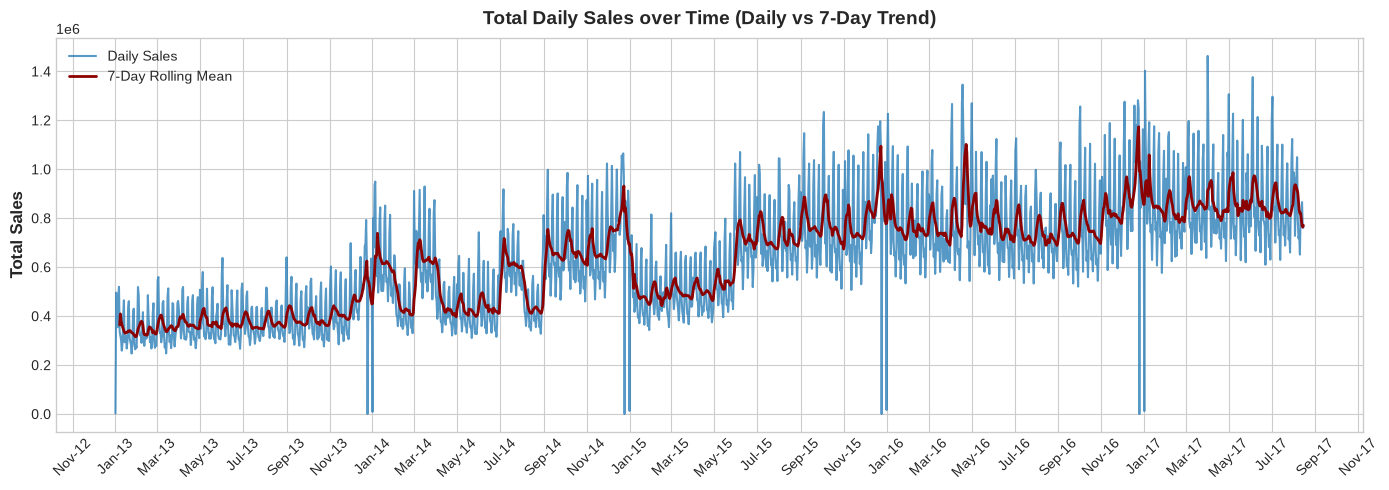

In [10]:
daily_sales = (
    df_train
    .groupby('date', as_index=False)['sales']
    .sum()
    .rename(columns={'sales': 'total_sales'})
)

# 7-day moving average
daily_sales['rolling_7d'] = daily_sales['total_sales'].rolling(7).mean()

# Daily sales
ax = sns.lineplot(
    data=daily_sales, 
    x='date', 
    y='total_sales',
    alpha=0.75,
    label='Daily Sales',
    )

# Superimposed 7-Day Rolling Mean
sns.lineplot(
    data=daily_sales,
    x='date',
    y='rolling_7d',
    ax=ax,
    color="darkred",
    linewidth=2,
    label="7-Day Rolling Mean",
)

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%y'))
plt.xticks(rotation=45, fontsize=10)
plt.ylabel('Total Sales')
plt.xlabel('')
plt.title('Total Daily Sales over Time (Daily vs 7-Day Trend)')
ax.legend(loc="upper left")
plt.show()

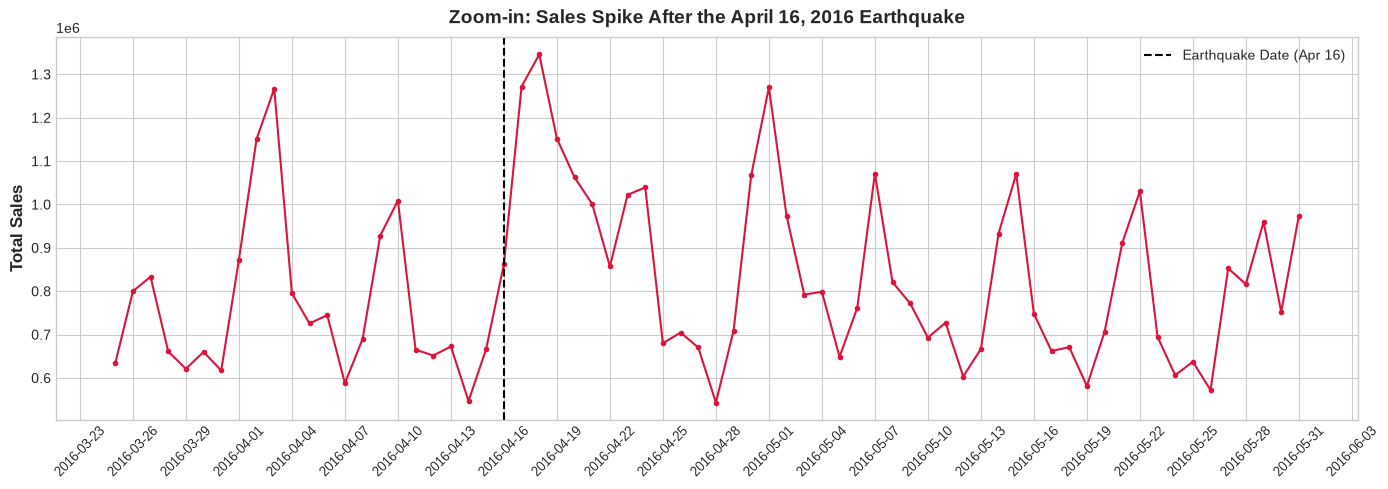

In [11]:
# Zoom-in around the earthquake period (March – April 2016)
earthquake_zoom = (
    daily_sales
    #~3 weeks prior and 6 weeks after the earthquake
    .query("date >= '2016-03-25' & date <= '2016-05-31'")
)

plt.plot(
    earthquake_zoom['date'],
    earthquake_zoom['total_sales'],
    marker='.',
    color='crimson',
)
plt.axvline(
    pd.to_datetime('2016-04-16'),
    color='black',
    linestyle='--',
    label='Earthquake Date (Apr 16)',
)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.xticks(rotation=45, fontsize=9)

plt.title('Zoom-in: Sales Spike After the April 16, 2016 Earthquake')
plt.ylabel('Total Sales')
plt.legend()
plt.show()

**Key Takeaways from Total Daily Sales:**
* **Long-Term Growth:** Sales show a clear upward trend from 2013 through mid-2017.
* **Recurring Seasonality:** Strong cyclical patterns remain visible even after 7-day smoothing, pointing to bi-weekly payday effects and end-of-year effects.
* **Christmas & New Year's Day Closures:** Sales drop to nearly zero on December 25 and January 1st every year when almost all stores are closed.
* **Earthquake Shock (April 2016):** A sharp, sustained sales spike occurs right after the April 16, 2016 earthquake in Ecuador due to emergency relief buying. Flagging this anomaly prevents tree models from distorting normal seasonal splits.

💡 **Features to build in Section 4:**
* `year`, `month`, `dayofyear`: Capture long-term growth and annual seasonality.
* `is_christmas` & `is_nyd`: Binary flags for Christmas and New Year's Day store closures.
* `is_earthquake_period`: Binary indicator derived directly from the `holiday_name` column (`Terremoto Manabi` and its 30-day post-event flags) to capture the massive demand shock and subsequent recovery in the affected region following the April 16, 2016 earthquake.

### 3.2 Product Family & Store Scale
Compare average daily sales across the top product families and top-performing stores to understand major scale differences.

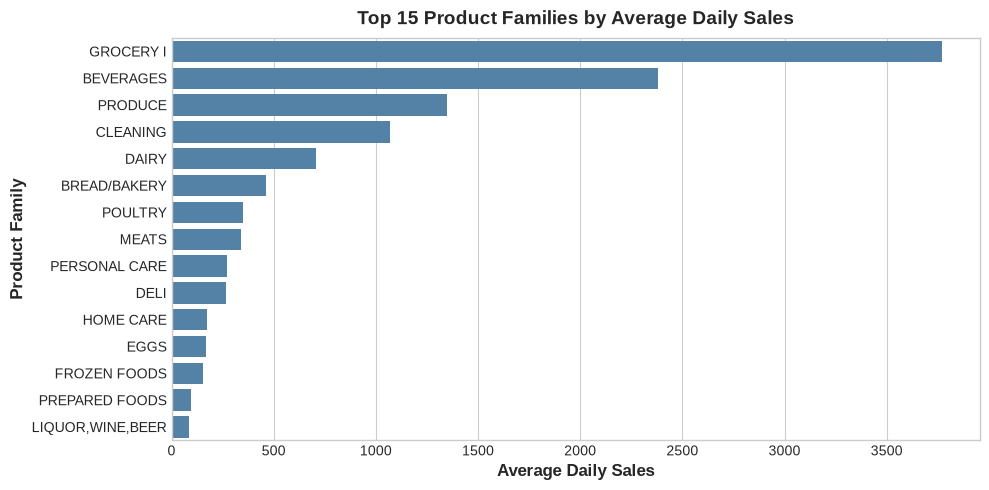

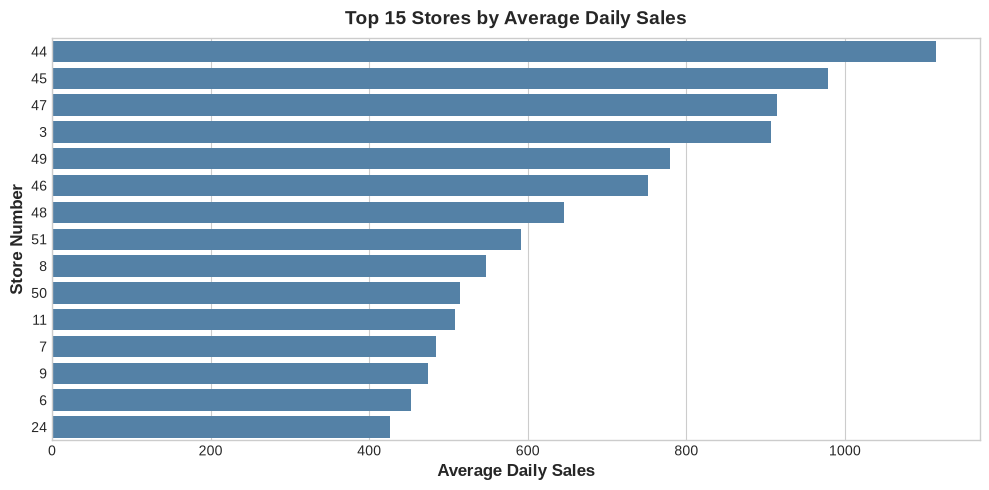

In [12]:
# Top 15 Product Families by Average Sales
top_families = (
    df_train.groupby('family', as_index=False)['sales']
    .mean()
    .sort_values(by='sales', ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_families, x='sales', y='family', color='steelblue')
plt.title('Top 15 Product Families by Average Daily Sales')
plt.xlabel('Average Daily Sales')
plt.ylabel('Product Family')
plt.show()

# Top 15 Stores by Average Sales
top_stores = (
    df_train.groupby('store_nbr', as_index=False)['sales']
    .mean()
    .sort_values(by='sales', ascending=False)
    .head(15)
)

top_stores['store_nbr'] = top_stores['store_nbr'].astype(str)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_stores, x='sales', y='store_nbr', color='steelblue')
plt.title('Top 15 Stores by Average Daily Sales')
plt.xlabel('Average Daily Sales')
plt.ylabel('Store Number')
plt.show()

**Key Takeaways on Families and Stores:**
* **Store Types & Family Categories:** Sales volume varies massively across product families (e.g., `GROCERY I` leading) and stores, justifying the inclusion of categorical identifiers (`family`, `store_nbr`, `store_type`, `cluster`).
* **Geographic Hierarchy (`city`, `state`):** Will retain alongside `store_nbr`, `store_type`, and `cluster` to allow tree models to group stores regionally with a single split. Particularly useful for isolating regional anomalies like the Manabi earthquake shock or local city-level demand patterns.

💡 **Features to build in Section 4:**
* `store_nbr`, `family`, `city`, `state`, `store_type`, `cluster` (plus `holiday_name`): Cast to `category` dtype on the combined dataset so tree-based models can perform optimal categorical splits.

### 3.3 Average Sales per Day of Month (Payday Effect)
In Ecuador, public sector wages are paid bi-weekly on the 15th and on the last day of the month. Here, we check how this payment schedule affects daily shopping behavior.

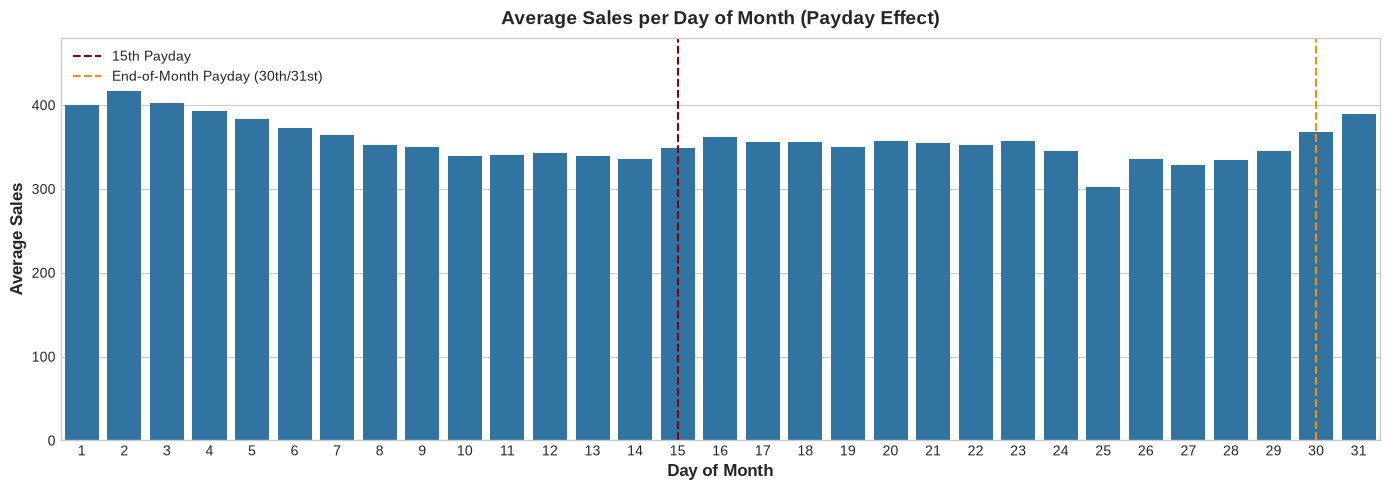

In [13]:
sales_per_dayofmonth = (
    df_train
    .assign(
        dayofmonth = lambda df: df['date'].dt.day
    )
    .groupby('dayofmonth', as_index=False)['sales']
    .mean()
    .rename(columns={'dayofmonth': 'day', 'sales': 'avg_sales'})
)

# Daily sales
ax = sns.barplot(
    data=sales_per_dayofmonth, 
    x='day', 
    y='avg_sales',
    )

plt.axvline(x=14, color='darkred', linestyle='--', linewidth=1.5, label='15th Payday')
plt.axvline(x=29, color='darkorange', linestyle='--', linewidth=1.5, label='End-of-Month Payday (30th/31st)')

plt.ylabel('Average Sales')
plt.xlabel('Day of Month')
plt.title('Average Sales per Day of Month (Payday Effect)')
plt.legend(loc='upper left')
plt.ylim(0, 480)
plt.show()

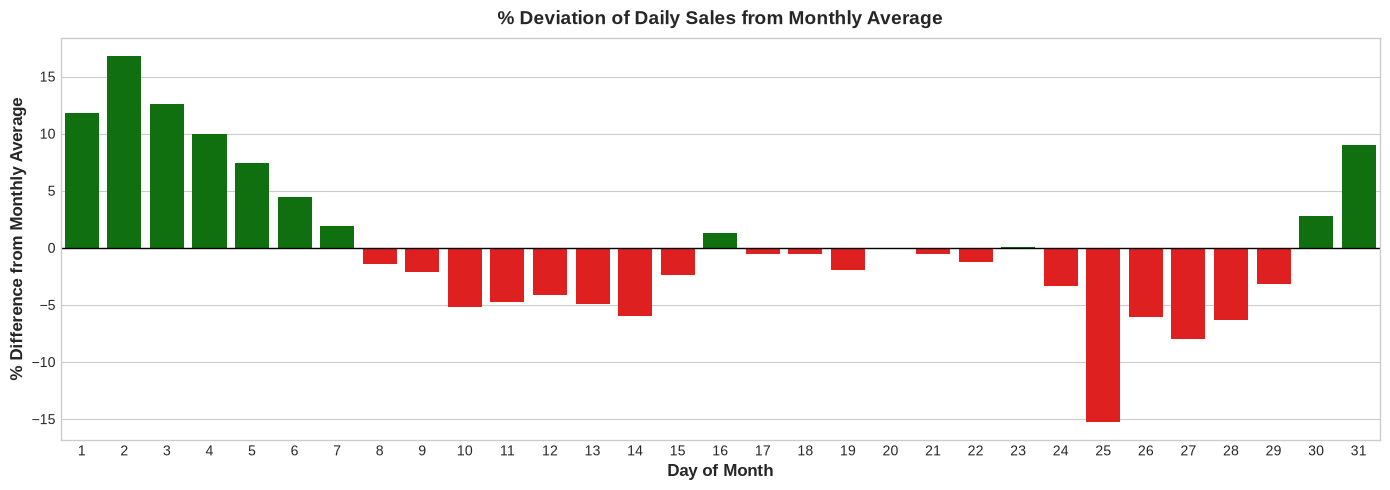

In [14]:
mean_sales = sales_per_dayofmonth['avg_sales'].mean()
sales_per_dayofmonth['pct_diff'] = ((sales_per_dayofmonth['avg_sales'] - mean_sales) / mean_sales) * 100

colors = ['green' if x > 0 else 'red' for x in sales_per_dayofmonth['pct_diff']]

ax = sns.barplot(
    data=sales_per_dayofmonth, 
    x='day', 
    y='pct_diff', 
    hue='day',
    palette=colors,
    legend=False
)

plt.axhline(0, color='black', linewidth=1)
plt.ylabel('% Difference from Monthly Average')
plt.xlabel('Day of Month')
plt.title('% Deviation of Daily Sales from Monthly Average')
plt.show()

**Key Takeaways from Monthly Sales Patterns (Payday Effect):**
* **Start-of-Month Surge (Days 1–4):** Sales are consistently highest during the first four days of the month (+10% to +17% above the monthly average), peaking on day 2 right after end-of-month paychecks are issued.
* **Mid-Month Bump (Days 15–16):** Sales dip to a local low on day 14 (-6%), then rebound on the 15th and turn positive on the 16th following the mid-month payday.
* **End-of-Month Uptick & Christmas Dip:** Sales rise again on days 30–31 (+3% to +9%), while the sharp dip on day 25 (-15%) is skewed by Christmas Day store closures.

💡 **Features to build in Section 4:**
* `dayofmonth`: Day of the month (1–31) to let tree models learn the daily trend.
* `is_month_start_end`: Binary indicator for days [1, 2, 3, 4, `is_month_end`] to capture the primary end-of-month paycheck wave (+10% to +17%).
* `is_mid_payday`: Binary indicator for days [15, 16] to isolate the secondary mid-month salary bump.

### 3.4 Average Sales per Weekday (Weekend Effect)
Examine how customer demand shifts across the days of the week (`Monday = 0` to `Sunday = 6`).

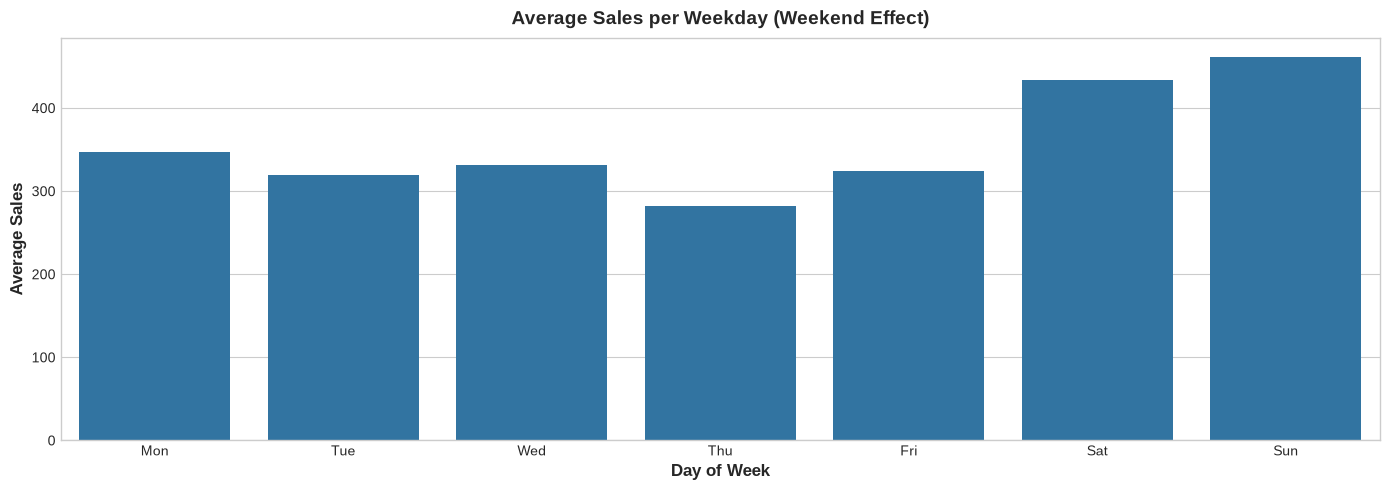

In [15]:
day_mapping = {
    0: 'Mon',
    1: 'Tue',
    2: 'Wed',
    3: 'Thu',
    4: 'Fri',
    5: 'Sat',
    6: 'Sun',
}

sales_per_weekday = (
    df_train
    .assign(weekday = lambda df: df['date'].dt.dayofweek)
    .groupby('weekday', as_index=False)['sales']
    .mean()
    .rename(columns={'sales': 'avg_sales'})
    .assign(weekday_name=lambda df: df['weekday'].map(day_mapping))
)

# Daily sales
ax = sns.barplot(
    data=sales_per_weekday, 
    x='weekday_name', 
    y='avg_sales',
    )

plt.ylabel('Average Sales')
plt.xlabel('Day of Week')
plt.title('Average Sales per Weekday (Weekend Effect)')
plt.show()

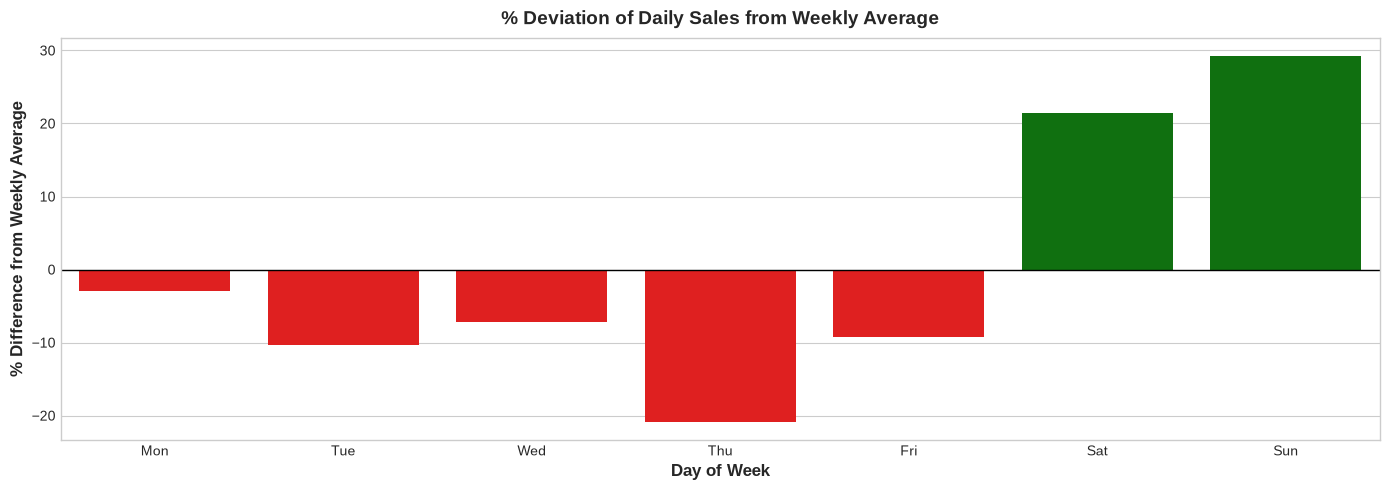

In [16]:
mean_sales = sales_per_weekday['avg_sales'].mean()
sales_per_weekday['pct_diff'] = ((sales_per_weekday['avg_sales'] - mean_sales) / mean_sales) * 100

colors = ['green' if x > 0 else 'red' for x in sales_per_weekday['pct_diff']]

ax = sns.barplot(
    data=sales_per_weekday, 
    x='weekday_name', 
    y='pct_diff', 
    hue='weekday_name',
    palette=colors,
    legend=False
)

plt.axhline(0, color='black', linewidth=1)
plt.ylabel('% Difference from Weekly Average')
plt.xlabel('Day of Week')
plt.title('% Deviation of Daily Sales from Weekly Average')
plt.show()

**Key Takeaways from Weekly Sales Patterns (Weekend Effect):**
* **Weekday (Monday–Friday):** Sales remain below the weekly average throughout the entire workweek. Monday is the strongest weekday, while Thursday is the slowest day of the week.
* **Weekend (Saturday–Sunday):** Retail traffic jumps sharply over the weekend, with sales rising **+21% on Saturday** and peaking at nearly **+30% above average on Sunday**.

💡 **Features to build in Section 4:**
* `dayofweek` (0–6): Standard day-of-week integer so tree-based models can learn the distinct pattern of each individual day (especially capturing the heavy weekend spike).

### 3.5 Oil Price vs. Sales
Ecuador's economy relies heavily on oil exports. Here, we check whether daily oil prices show a direct linear relationship with total retail sales across each year.

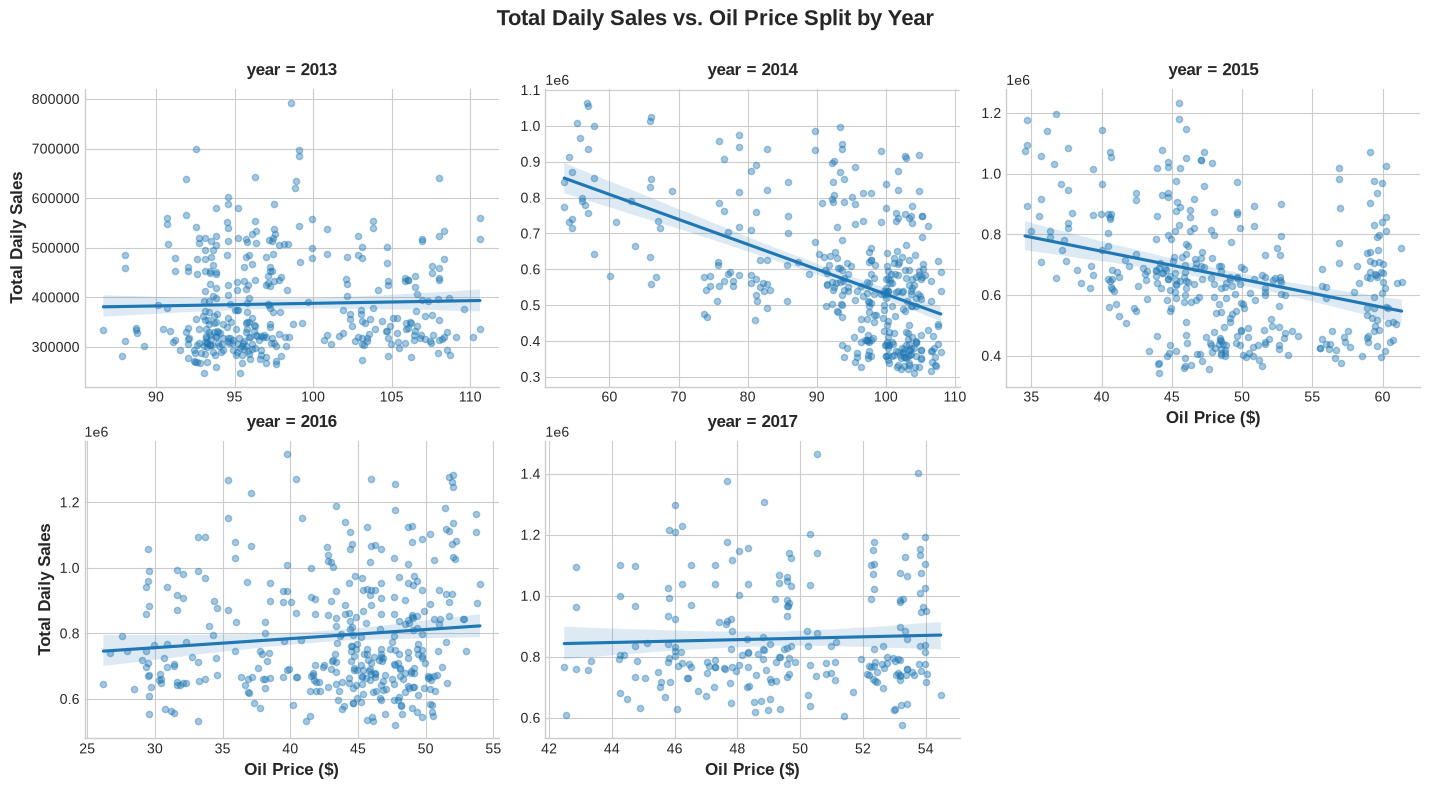

In [17]:
daily_oil = (
    df_train[['date', 'oil_price']]
    .drop_duplicates('date')
    .sort_values('date')
)

oil_vs_sales = (
    pd.merge(daily_sales, daily_oil, on='date', how='inner')
    .query('total_sales > 100000')  # Exclude Christmas and New Year's Day closures (outliers with very low or 0 sales)
    .assign(year=lambda df: df['date'].dt.year)
)

g = sns.lmplot(
    data=oil_vs_sales,
    x='oil_price',
    y='total_sales',
    col='year',
    col_wrap=3,
    height=4,
    aspect=1.2,
    scatter_kws={'alpha': 0.4, 's': 20},
    facet_kws={
        'sharex': False,
        'sharey': False,
    },
)

g.set_axis_labels('Oil Price ($)', 'Total Daily Sales')
g.figure.subplots_adjust(top=0.88)
g.figure.suptitle('Total Daily Sales vs. Oil Price Split by Year', fontsize=16, fontweight='bold')
plt.show()

**Key Takeaways on Oil Prices & Sales:**
* **No Direct Day-to-Day Link:** Looking at each year separately shows that daily oil price fluctuations do not directly drive everyday grocery shopping. The apparent negative slope in 2014–2015 is probably a coincidence of two macro trends: global oil prices crashed (from ~100$ down to 40$) while the supermarket chain was steadily growing.

💡 **Features to build in Section 4 based on these plots:**
* `oil_price`: Raw imputed daily oil price to let tree-based models capture broad macroeconomic regime changes.

### 3.6 Promotions vs. Sales
Examine the distribution of `onpromotion` (number of items on promotion within a store-family) and its impact on sales.

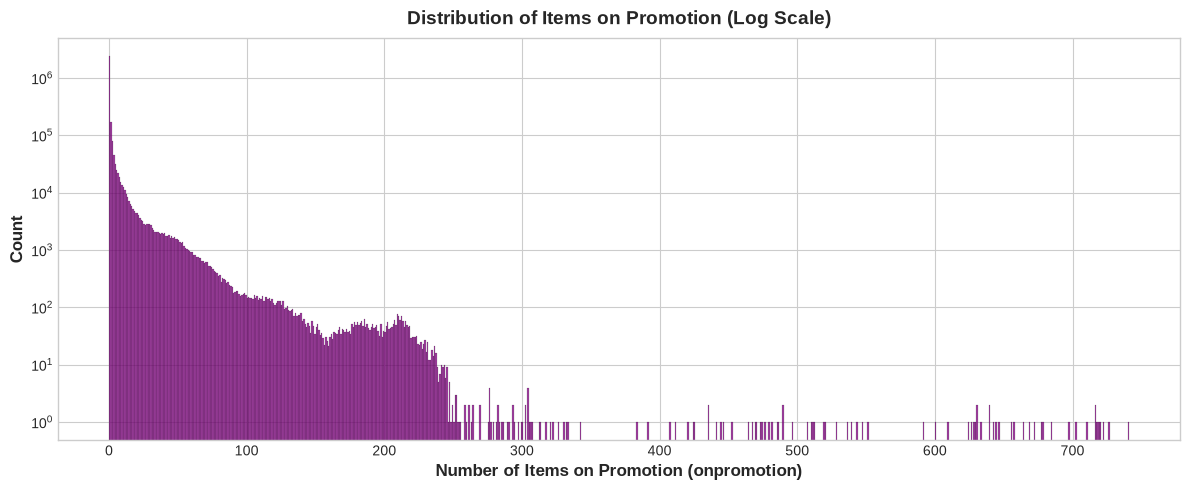

In [18]:
plt.figure(figsize=(12, 5))
sns.histplot(
    data=df_train,
    x='onpromotion',
    binwidth=1,
    color='purple',
)
plt.yscale('log')
plt.title('Distribution of Items on Promotion (Log Scale)')
plt.xlabel('Number of Items on Promotion (onpromotion)')
plt.ylabel('Count')
plt.show()


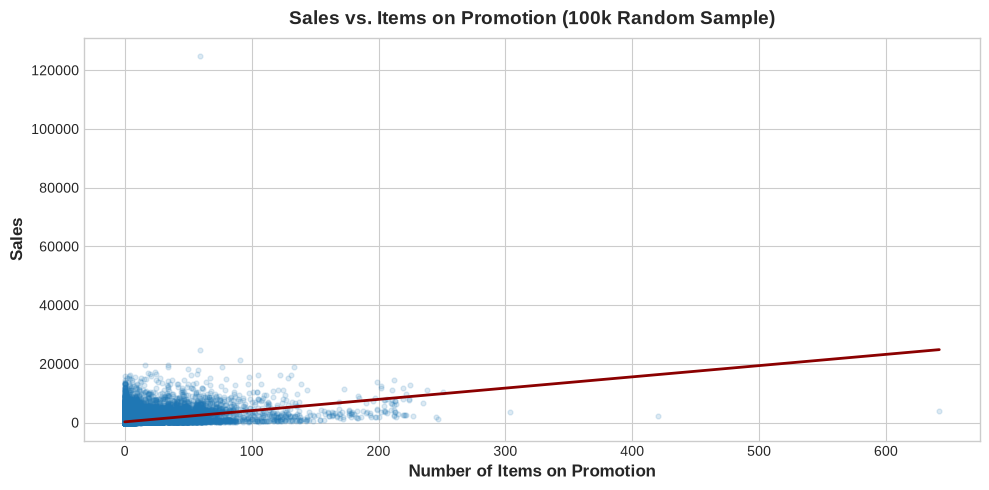

In [19]:
df_sample = df_train.sample(n=100000, random_state=0)

plt.figure(figsize=(10, 5))
sns.regplot(
    data=df_sample,
    x='onpromotion',
    y='sales',
    ci=None,
    scatter_kws={'alpha': 0.15, 's': 12},
    line_kws={'color': 'darkred', 'linewidth': 2},
)
plt.title('Sales vs. Items on Promotion (100k Random Sample)')
plt.xlabel('Number of Items on Promotion')
plt.ylabel('Sales')
plt.show()

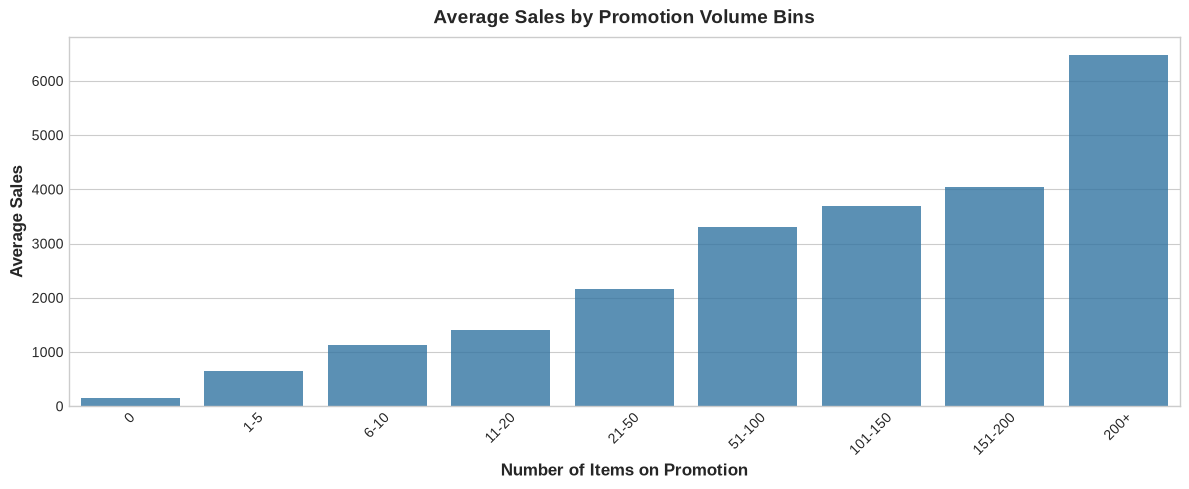

In [20]:
bins = [-1, 0, 5, 10, 20, 50, 100, 150, 200, 1000]
labels = [
    '0',
    '1-5',
    '6-10',
    '11-20',
    '21-50',
    '51-100',
    '101-150',
    '151-200',
    '200+',
]

promo_binned = (
    df_train.assign(
        promo_bin=pd.cut(
            df_train['onpromotion'], bins=bins, labels=labels
        )
    )
    .groupby('promo_bin', as_index=False, observed=False)['sales']
    .mean()
    .rename(columns={'sales': 'avg_sales'})
)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=promo_binned, 
    x='promo_bin', 
    y='avg_sales', 
    alpha=0.8
)
plt.title('Average Sales by Promotion Volume Bins',)
plt.xlabel('Number of Items on Promotion')
plt.ylabel('Average Sales')
plt.xticks(rotation=45)
plt.show()

In [21]:
temp_df = df_train[['date', 'store_nbr', 'family', 'sales', 'onpromotion']].copy()

temp_df['promo_lag_1'] = temp_df.groupby(['store_nbr', 'family'])['onpromotion'].shift(1)
temp_df['promo_lead_1'] = temp_df.groupby(['store_nbr', 'family'])['onpromotion'].shift(-1)

print('Correlation with sales:')
print(f"Same day (onpromotion): {temp_df['sales'].corr(temp_df['onpromotion']):.3f}")
print(f"Previous day (lag_1):   {temp_df['sales'].corr(temp_df['promo_lag_1']):.3f}")
print(f"Next day (lead_1):      {temp_df['sales'].corr(temp_df['promo_lead_1']):.3f}")

Correlation with sales:
Same day (onpromotion): 0.428
Previous day (lag_1):   0.373
Next day (lead_1):      0.376


**Key Takeaways on Promotions (`onpromotion`):**
* **Strong Positive Impact:** While the raw data is heavily zero-inflated (most store-family pairs have zero active promotions on a given day), grouping `onpromotion` into volume bins reveals a strong, step-by-step increase in average sales as promotion counts rise.
* **High Predictive Value:** Since `onpromotion` is known in advance for the entire 16-day test set, it serves as a direct, leak-free predictor of future demand. Same-day promotion counts correlate more strongly with sales ($r = 0.428$) than 1-day lags or leads.

💡 **Features to build in Section 4:**
* `onpromotion`: Raw numerical count of items on promotion per store/family daily.
* *Omit Lags/Leads:* Kept simple using only current-day promotions, as they have a stronger correlation with sales and avoid unnecessary complexity.
* *Omit `has_promotion`:* Redundant for tree-based models, since a single split on the raw numerical `onpromotion` (`> 0`) already captures this exact information.

### 3.7 Store Transactions vs. Sales
Store-level `transactions` are only recorded up to the end of the training period (`2017-08-15`) and are not available during the 16-day test window (`2017-08-16` to `2017-08-31`). To prevent **data leakage**, any transaction feature must be shifted by at least 16 calendar days. Here, we build a complete `(date x store_nbr)` calendar grid and compare same-day transactions (benchmark) against leak-free lagged and rolling transaction features at the store level.

In [22]:
# All dates from 2013-01-01 up to 2017-08-31
all_dates = pd.date_range(
    start=df_transactions['date'].min(),
    end='2017-08-31',
    freq='D',
)

# All stores (store_nbr = 1-54)
all_stores = df_transactions['store_nbr'].unique()

# Full grid of dates x stores
full_grid = (
    pd.MultiIndex.from_product(
        [all_dates, all_stores], names=['date', 'store_nbr']
    )
    .to_frame()
    .reset_index(drop=True)
)

# New transactions table
df_transactions_complete = (
    pd.merge(
        full_grid,
        df_transactions,
        on=['date', 'store_nbr'],
        how='left',
    )
    .sort_values(by=['store_nbr', 'date'])
    .fillna(0)
    .assign(
        transactions_lag16 = lambda df: df.groupby('store_nbr')['transactions'].shift(16),
        transactions_lag16_rolling_mean_14 = lambda df: (
            df
            .groupby('store_nbr')['transactions_lag16']
            .transform(lambda s: s.rolling(14, min_periods=1).mean())
        ),
        transactions_lag16_rolling_mean_28 = lambda df: (
            df
            .groupby('store_nbr')['transactions_lag16']
            .transform(lambda s: s.rolling(28, min_periods=1).mean())
        ),
        transactions_lag16_rolling_std_14 = lambda df: (
            df
            .groupby('store_nbr')['transactions_lag16']
            .transform(lambda s: s.rolling(14, min_periods=1).std()).fillna(0.0)
        ),
        transactions_lag16_rolling_std_28 = lambda df: (
            df
            .groupby('store_nbr')['transactions_lag16']
            .transform(lambda s: s.rolling(28, min_periods=1).std()).fillna(0.0)
        ),
    )
)

# Merge the new transactions table with the train table
df_train_transactions = (
    df_train
    .merge(
        df_transactions_complete,
        on=['date', 'store_nbr'],
        how='left'
    )
    .query('date >= "2013-03-01"')
)

df_store_daily = (
    df_train_transactions.groupby(['date', 'store_nbr'], as_index=False).agg(
        total_sales=('sales', 'sum'),
        transactions=('transactions', 'first'),
        transactions_lag16=('transactions_lag16', 'first'),
        transactions_lag16_rolling_mean_14=('transactions_lag16_rolling_mean_14', 'first'),
        transactions_lag16_rolling_mean_28=('transactions_lag16_rolling_mean_28', 'first'),
        transactions_lag16_rolling_std_14=('transactions_lag16_rolling_std_14', 'first'),
        transactions_lag16_rolling_std_28=('transactions_lag16_rolling_std_28', 'first')
    )
    .sort_values(by=['store_nbr', 'date'])
)

display(df_store_daily)
print_perc_of_nans(df=df_store_daily, col_names=list(df_store_daily.columns), name='Daily Sales vs. Transaction Features')

,date,store_nbr,total_sales,transactions,transactions_lag16,transactions_lag16_rolling_mean_14,transactions_lag16_rolling_mean_28,transactions_lag16_rolling_std_14,transactions_lag16_rolling_std_28
0,2013-03-01,1,5940.556000,1916,1921,1332.142857,1431.857143,619.147784,543.911942
54,2013-03-02,1,5817.466999,1332,2119,1361.571429,1443.750000,647.478745,555.460211
108,2013-03-03,1,2436.827000,547,1787,1360.214286,1445.250000,646.494712,556.359837
162,2013-03-04,1,6094.491999,1841,1263,1352.071429,1440.750000,646.984777,557.340352
216,2013-03-05,1,4968.634010,1750,399,1342.642857,1436.892857,660.687475,564.371190
...,...,...,...,...,...,...,...,...,...
87749,2017-08-11,54,8513.834000,768,700,767.714286,794.035714,101.406591,111.555162
87803,2017-08-12,54,9139.678002,903,662,766.214286,792.071429,102.900384,113.430327
87857,2017-08-13,54,14246.827996,1054,766,772.642857,794.250000,99.588853,112.275991
87911,2017-08-14,54,11882.994000,818,870,773.714286,790.642857,100.618417,107.925288


Daily Sales vs. Transaction Features - date: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - store_nbr: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - total_sales: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - transactions: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - transactions_lag16: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - transactions_lag16_rolling_mean_14: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - transactions_lag16_rolling_mean_28: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - transactions_lag16_rolling_std_14: 0 NaNs out of 87,966 (0.0%)
Daily Sales vs. Transaction Features - transactions_lag16_rolling_std_28: 0 NaNs out of 87,966 (0.0%)


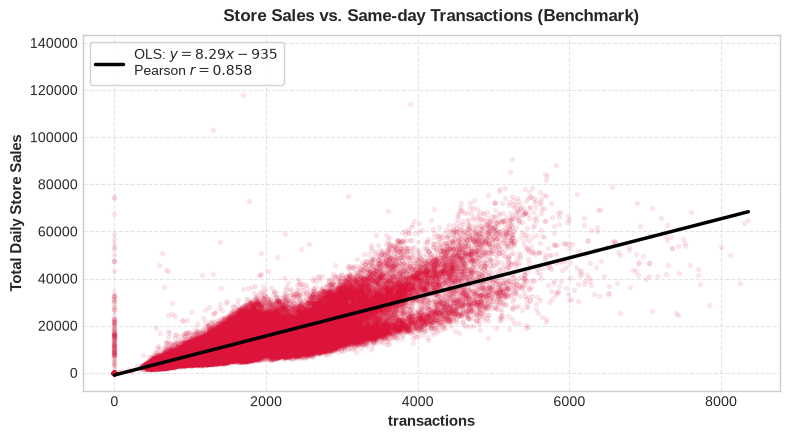

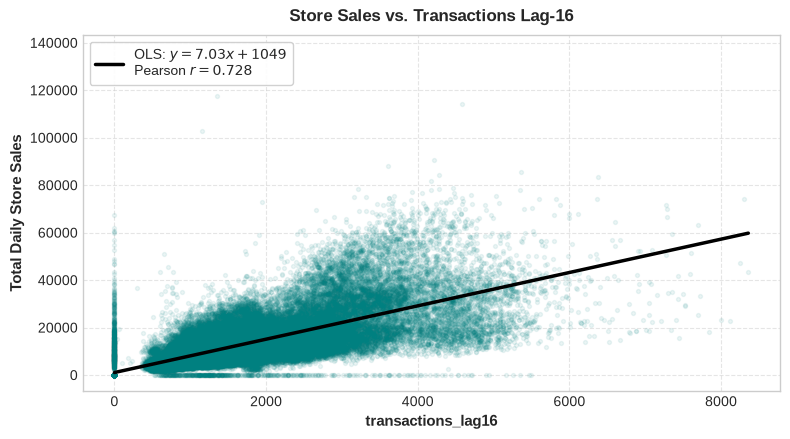

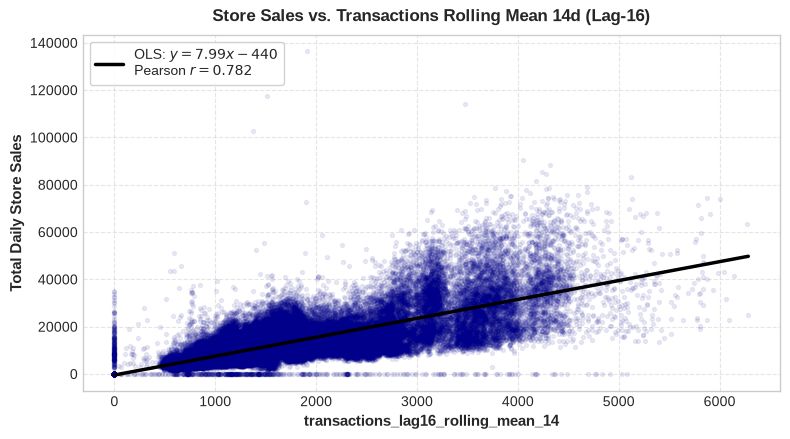

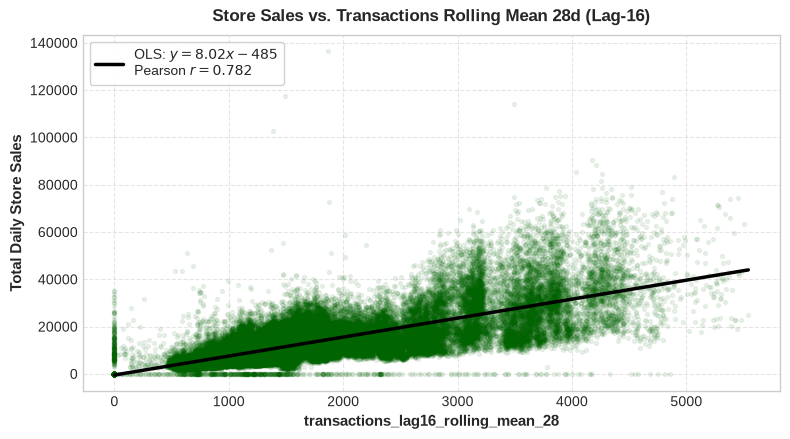

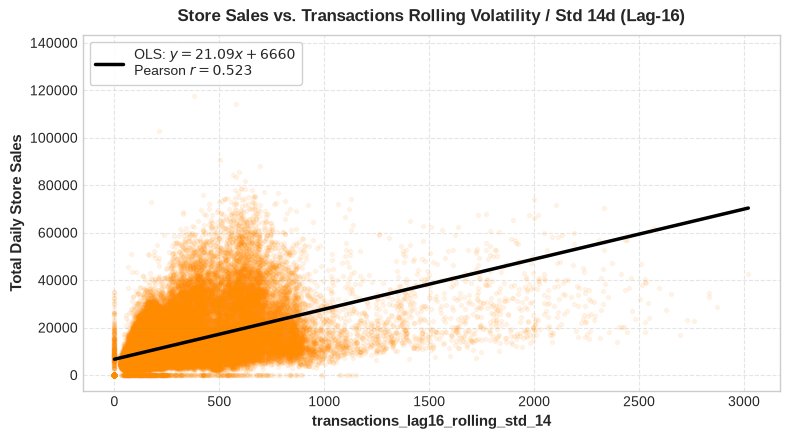

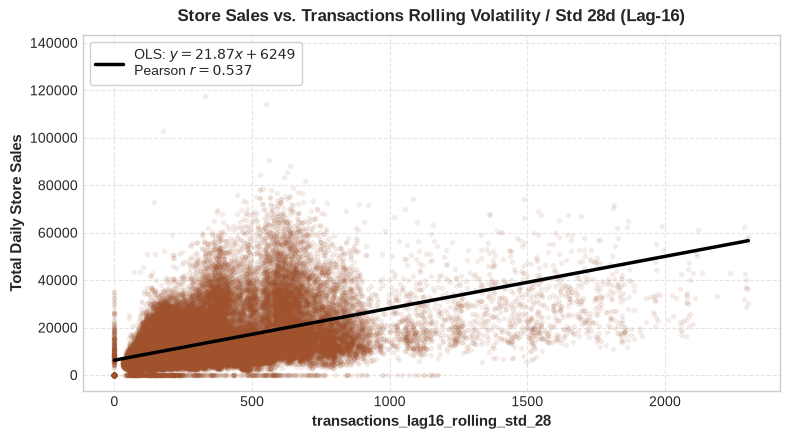

In [23]:
features_config = [
    ('transactions', 'Same-day Transactions (Benchmark)', 'crimson'),
    ('transactions_lag16', 'Transactions Lag-16', 'teal'),
    ('transactions_lag16_rolling_mean_14', 'Transactions Rolling Mean 14d (Lag-16)', 'darkblue'),
    ('transactions_lag16_rolling_mean_28', 'Transactions Rolling Mean 28d (Lag-16)', 'darkgreen'),
    ('transactions_lag16_rolling_std_14', 'Transactions Rolling Volatility / Std 14d (Lag-16)', 'darkorange'),
    ('transactions_lag16_rolling_std_28', 'Transactions Rolling Volatility / Std 28d (Lag-16)', 'sienna'),
]

for col, title, color in features_config:

    # Calculation of Pearson r
    r = df_store_daily['total_sales'].corr(df_store_daily[col])

    # Slope and intercept of: y = ax + b
    slope, intercept = np.polyfit(df_store_daily[col], df_store_daily['total_sales'], deg=1)

    legend_label = (
        f'OLS: $y = {slope:.2f}x {intercept:+.0f}$\nPearson $r = {r:.3f}$'
    )

    plt.figure(figsize=(8, 4.5))
    ax = sns.regplot(
        data=df_store_daily,
        x=col,
        y='total_sales',
        color=color,
        ci=None,
        scatter_kws={'alpha': 0.08, 's': 8},
        line_kws={'linewidth': 2.5, 'color': 'black', 'label': legend_label},
    )

    plt.title(f'Store Sales vs. {title}', fontweight='bold', fontsize=12)
    plt.xlabel(col, fontsize=11)
    plt.ylabel('Total Daily Store Sales', fontsize=11)

    plt.legend(
        loc='upper left',
        frameon=True,
        facecolor='white',
        framealpha=0.9,
        fontsize=10,
    )
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

**Key Takeaways on Store Transactions:**
* **Benchmark vs. Leak-Free Features ($r = 0.858 \to r = 0.782$):** Same-day `transactions` has the strongest linear correlation with store sales ($r = 0.858$), but using it directly would cause **severe data leakage** since future transactions are unknown in the test set.
* **Strong Historical Signal:** Shifting transactions by 16 calendar days (`transactions_lag16`, $r = 0.728$) and smoothing over 14-day and 28-day rolling windows ($r = 0.782$) recovers most of that predictive power without any leakage.
* **Store-Level Macro Context:** Broadcasting these store-level traffic features across all 33 product families gives tree models a reliable measure of each store's overall size and recent footfall momentum.

> **Note on Training Sample Window:**  
> The first two months of the dataset (January and February 2013) will be excluded from model training (`date >= '2013-03-01'`). A 16-day lag combined with a 28-day rolling window requires 44 continuous calendar days to warm up, reaching full window saturation in mid-February 2013. Starting from March 1st eliminates partial-window artifacts and ensures consistent feature quality.

💡 **Features to build in Section 4:**
* `transactions_lag16`: Store transactions shifted by 16 calendar days.
* `transactions_lag16_rolling_mean_14`: 14-day rolling average of `transactions_lag16` per store.
* `transactions_lag16_rolling_mean_28`: 28-day rolling average of `transactions_lag16` per store.
* `transactions_lag16_rolling_std_14`: 14-day rolling standard deviation over `transactions_lag16`.
* `transactions_lag16_rolling_std_28`: 28-day rolling standard deviation over `transactions_lag16`.

### 3.8 Target Distribution (RMSLE) & Lagged Sales Autocorrelation
The competition evaluation metric is **Root Mean Squared Logarithmic Error (RMSLE)**, meaning that minimizing standard RMSE on $\log(\text{sales} + 1)$ directly optimizes the competition metric. In addition, since the forecast horizon is 16 days, historical sales lags (`lag >= 16`) for each specific `(store_nbr, family)` series are essential to anchor the model's predictions. Here, we inspect both the log-transformed target distribution and the autocorrelation of lagged sales features.

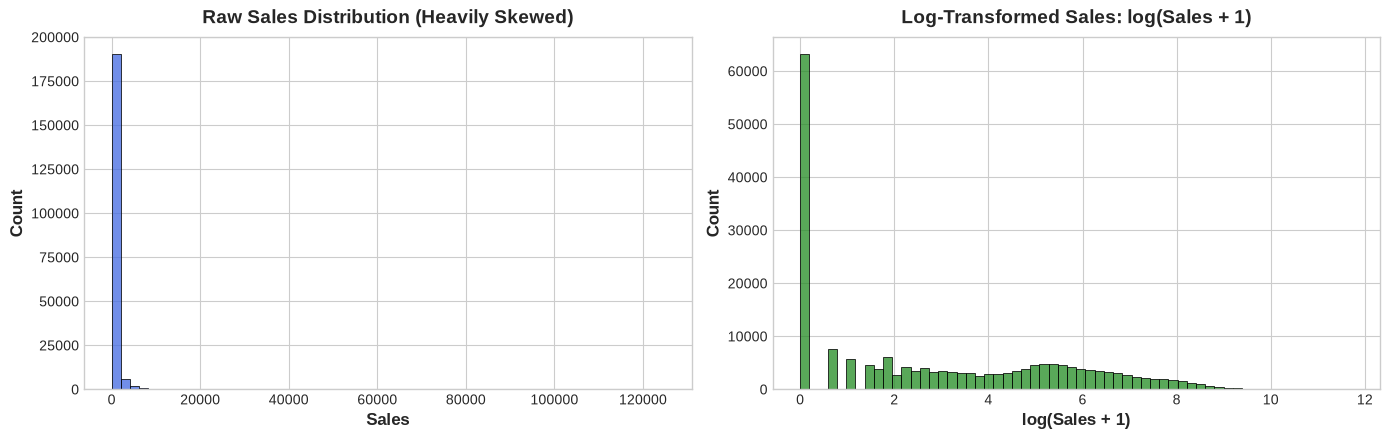

In [24]:
sample_sales = df_train['sales'].sample(n=200000, random_state=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot 1: Raw Sales Distribution
sns.histplot(sample_sales, bins=60, ax=axes[0], color='royalblue', kde=False)
axes[0].set_title('Raw Sales Distribution (Heavily Skewed)', fontweight='bold')
axes[0].set_xlabel('Sales')
axes[0].set_ylabel('Count')

# Plot 2: Log1p Sales Distribution
sns.histplot(np.log1p(sample_sales), bins=60, ax=axes[1], color='forestgreen', kde=False)
axes[1].set_title('Log-Transformed Sales: log(Sales + 1)', fontweight='bold')
axes[1].set_xlabel('log(Sales + 1)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [25]:
df_sales = (
    df_train
    .sort_values(['store_nbr', 'family', 'date'])
    .assign(
        sales_lag16 = lambda df: df.groupby(['store_nbr', 'family'])['sales'].shift(16),
        sales_lag21 = lambda df: df.groupby(['store_nbr', 'family'])['sales'].shift(21),
        sales_lag28 = lambda df: df.groupby(['store_nbr', 'family'])['sales'].shift(28),
        sales_lag35 = lambda df: df.groupby(['store_nbr', 'family'])['sales'].shift(35),

        #Same-Day-of-Week 3-week average (3, 4, and 5 weeks ago)
        sales_dow_mean_3w = lambda df: (df['sales_lag21'] + df['sales_lag28'] + df['sales_lag35'])/3.0,

        sales_lag21_rolling_mean_14 = lambda df: (
            df.groupby(['store_nbr', 'family'])['sales_lag21']
            .transform(lambda s: s.rolling(window=14, min_periods=1).mean())
        ),

        sales_lag21_rolling_mean_28 = lambda df: (
            df.groupby(['store_nbr', 'family'])['sales_lag21']
            .transform(lambda s: s.rolling(window=28, min_periods=1).mean())
        ),

        sales_lag21_rolling_std_14 = lambda df: (
            df.groupby(['store_nbr', 'family'])['sales_lag21']
            .transform(lambda s: s.rolling(window=14, min_periods=1).std())
            .fillna(0.0)
        ),

        sales_lag21_rolling_std_28 = lambda df: (
            df.groupby(['store_nbr', 'family'])['sales_lag21']
            .transform(lambda s: s.rolling(window=28, min_periods=1).std())
            .fillna(0.0)
        ),
    )
    .query('date >= "2013-03-01"')
)

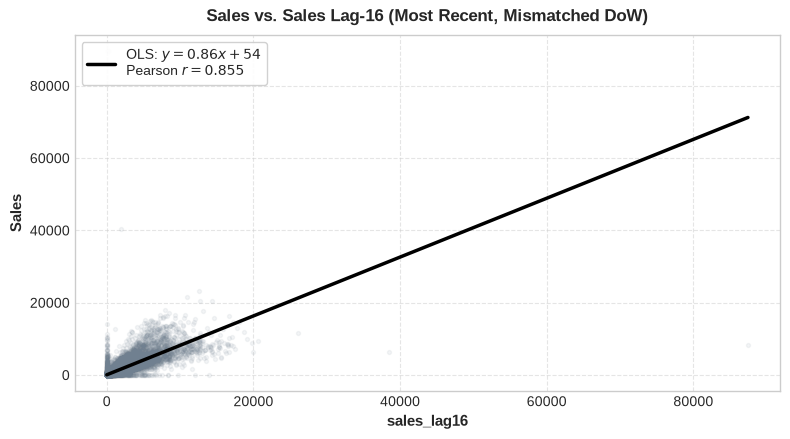

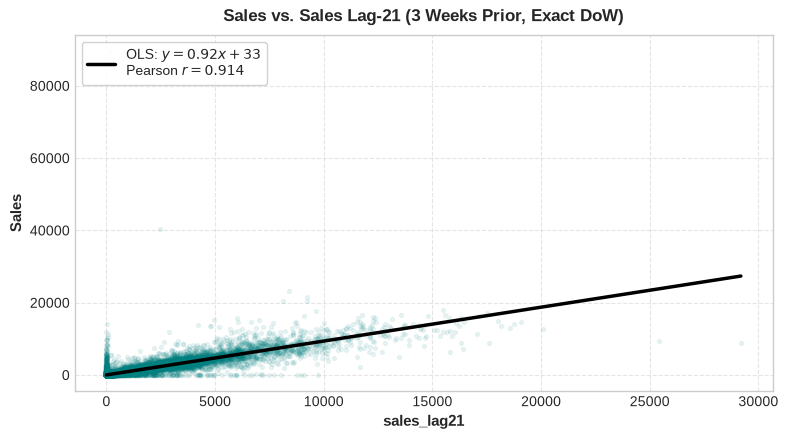

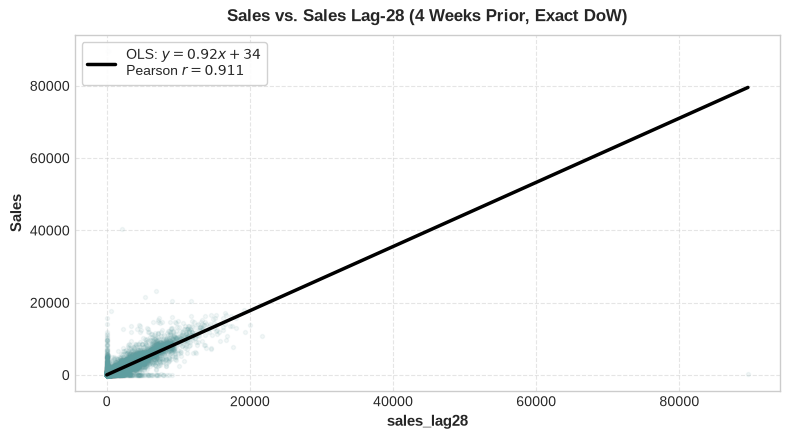

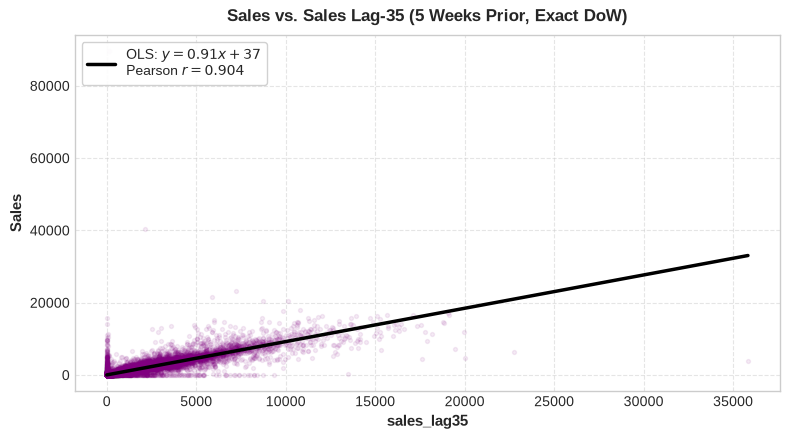

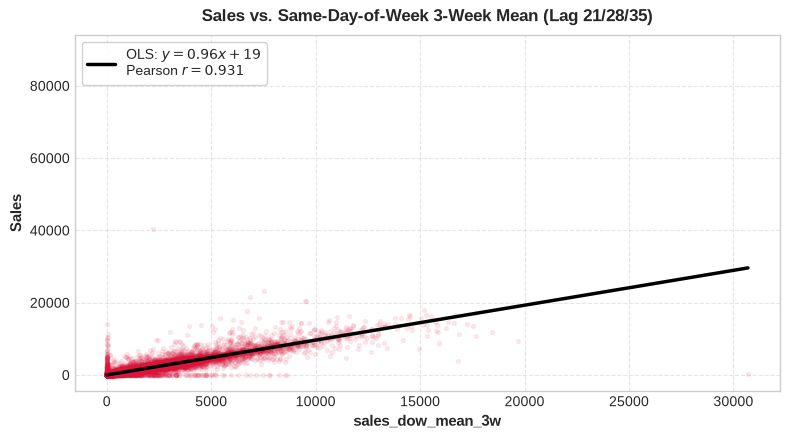

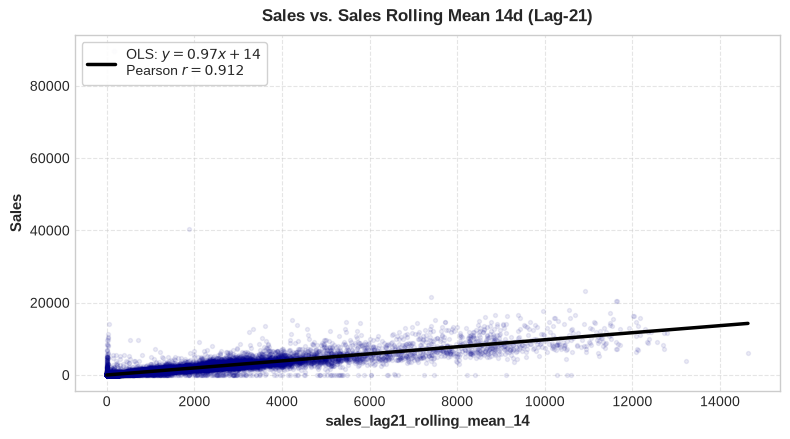

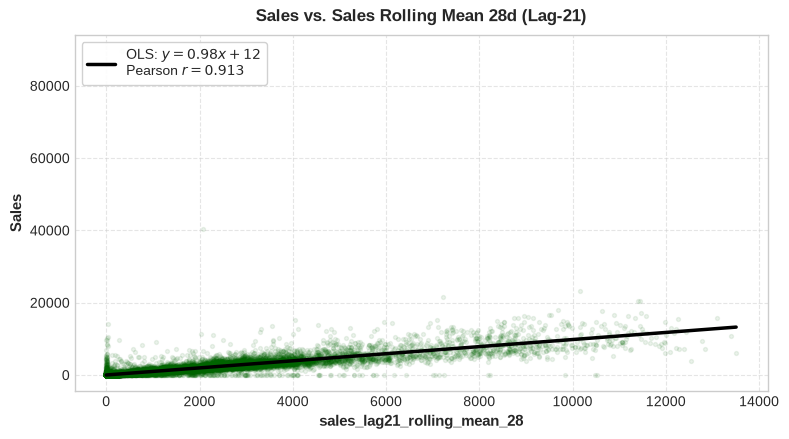

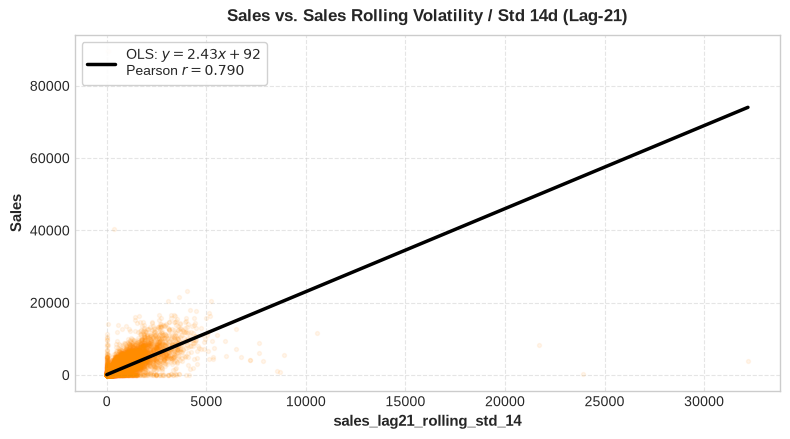

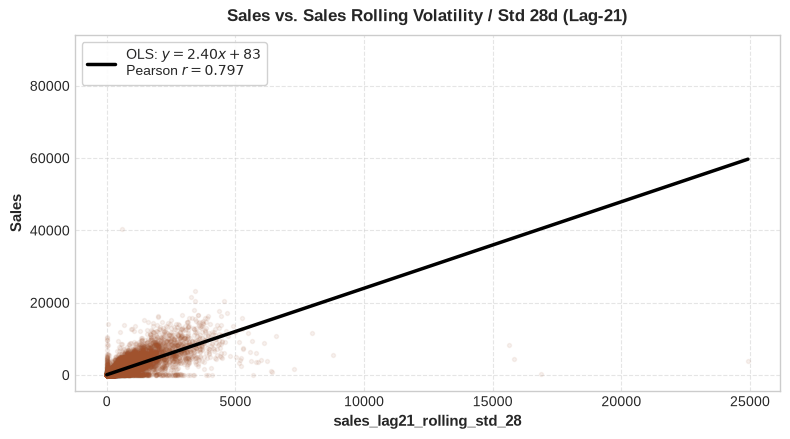

In [26]:
features_sales_config = [
    ('sales_lag16',                 'Sales Lag-16 (Most Recent, Mismatched DoW)',   'slategray'),
    ('sales_lag21',                 'Sales Lag-21 (3 Weeks Prior, Exact DoW)',      'teal'),
    ('sales_lag28',                 'Sales Lag-28 (4 Weeks Prior, Exact DoW)',      'cadetblue'),
    ('sales_lag35',                 'Sales Lag-35 (5 Weeks Prior, Exact DoW)',      'purple'),
    ('sales_dow_mean_3w',           'Same-Day-of-Week 3-Week Mean (Lag 21/28/35)',  'crimson'),
    ('sales_lag21_rolling_mean_14', 'Sales Rolling Mean 14d (Lag-21)',              'darkblue'),
    ('sales_lag21_rolling_mean_28', 'Sales Rolling Mean 28d (Lag-21)',              'darkgreen'),
    ('sales_lag21_rolling_std_14',  'Sales Rolling Volatility / Std 14d (Lag-21)',  'darkorange'),
    ('sales_lag21_rolling_std_28',  'Sales Rolling Volatility / Std 28d (Lag-21)',  'sienna')
]

df_sales_sample = df_sales.sample(n=100000, random_state=0)

for col, title, color in features_sales_config:

    # Calculation of Pearson r
    r = df_sales['sales'].corr(df_sales[col])

    # Slope and intercept of: y = ax + b
    slope, intercept = np.polyfit(df_sales[col], df_sales['sales'], deg=1)

    legend_label = (
        f'OLS: $y = {slope:.2f}x {intercept:+.0f}$\nPearson $r = {r:.3f}$'
    )

    plt.figure(figsize=(8, 4.5))
    ax = sns.regplot(
        data=df_sales_sample,
        x=col,
        y='sales',
        color=color,
        ci=None,
        scatter_kws={'alpha': 0.08, 's': 8},
        line_kws={'linewidth': 2.5, 'color': 'black', 'label': legend_label},
    )

    plt.title(f'Sales vs. {title}', fontweight='bold', fontsize=12)
    plt.xlabel(col, fontsize=11)
    plt.ylabel('Sales', fontsize=11)

    plt.legend(
        loc='upper left',
        frameon=True,
        facecolor='white',
        framealpha=0.9,
        fontsize=10,
    )
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

**Key Takeaways on Target Log-Transformation & Sales Autocorrelation:**
* **Distribution Regularization & RMSLE Alignment:** Raw sales are heavily right-skewed with extreme outliers. Applying $\log(1 + \text{sales})$ compresses extreme scales, stabilizes variance across store-family pairs, and allows gradient boosting models trained with standard MSE loss to directly optimize RMSLE.
* **Recency (`lag16`) vs. Day-of-Week Alignment (`lag21`, `lag28`, `lag35`):** While `sales_lag16` is the most recent leak-free observation for a 16-day forecast horizon, it falls on a different day of the week (2 weeks + 2 days prior). Conversely, multiples of 7 (`lag21`, `lag28`, `lag35`) align with the **exact same day of the week** 3, 4, and 5 weeks prior, yielding a noticeably stronger correlation with current sales. We include both in our feature matrix and let our Ablation Study in Notebook 03 empirically test whether recency (`lag16`) adds value on top of aligned weekly lags.
* **Same-Day-of-Week Rolling Mean (`sales_log1p_dow_mean_3w`):** Averaging the last three aligned weekdays (`(lag21 + lag28 + lag35) / 3`) filters out single-week anomalies while preserving the exact weekday scale (e.g., Sunday vs. Tuesday demand), achieving the highest autocorrelation among all historical predictors.
* **Demand Volatility (`sales_log1p_lag21_rolling_std_14` & `sales_log1p_lag21_rolling_std_28`):** Two series can share the same 14-day (or 28-day) rolling mean while exhibiting completely different behaviors (steady daily staples vs. erratic promotional bursts). Including the 14- and 28-day rolling standard deviation gives tree models a direct measure of local demand variance.

💡 **Features to build in Section 4:**
* `sales_log1p`: Target variable transformed via `np.log1p(sales)` for model training.
* `sales_log1p_lag16`, `sales_log1p_lag21`, `sales_log1p_lag28`, `sales_log1p_lag35`: Point-in-time historical log-sales lags.
* `sales_log1p_dow_mean_3w`: Mean of `lag21`, `lag28`, and `lag35` capturing smoothed same-weekday demand.
* `sales_log1p_lag21_rolling_mean_14` & `sales_log1p_lag21_rolling_mean_28`: 14-day and 28-day rolling averages over `sales_log1p_lag21`.
* `sales_log1p_lag21_rolling_std_14` & `sales_log1p_lag21_rolling_std_28`: 14- and 28-day rolling standard deviation over `sales_log1p_lag21`.

# 4. Feature Engineering Pipeline
Consolidate all domain insights from Section 3 into a modular, leak-free feature engineering pipeline. 

**Pipeline Architecture & Key Design Choices:**
* **Chronological Train + Test Concatenation:** `df_train` and `df_test` are temporarily merged into a single continuous timeline (`df_full`) sorted by `(store_nbr, family, date)`. This allows historical sales and transaction lags to flow seamlessly across the `2017-08-16` boundary into the 16-day test set without generating `NaN` values.
* **Memory Optimization & Unified Categoricals:** Calendar and binary flags are downcast to `int8`/`int16`, and categorical identifiers are cast to `category` on `df_full` prior to splitting so that both train and test sets share identical category encodings.
* **Warm-Up Window Trimming (`date >= '2013-03-01'`):** The first two months of 2013 are used strictly as a historical buffer to saturate the 21-day lags and 28-day rolling averages, and are trimmed before exporting the final training matrix.

In [27]:
# Free up memory from large intermediate EDA DataFrames before building df_full

vars_to_delete = [
    'temp_df',                 
    'df_train_transactions',   
    'df_sales',                
    'df_sample',               
    'df_sales_sample',         
    'sample_sales',            
    'oil_vs_sales'             
]

for var in vars_to_delete:
    if var in globals():
        del globals()[var]

gc.collect()

75488

In [28]:
def add_calendar_and_event_features(df: pd.DataFrame) -> pd.DataFrame:
    """Create calendar, payday, and event/anomaly flags."""
    return (
        df
        .assign(
            year = lambda x: x['date'].dt.year.astype('int16'),
            month = lambda x: x['date'].dt.month.astype('int8'),
            dayofmonth = lambda x: x['date'].dt.day.astype('int8'),
            dayofweek = lambda x: x['date'].dt.dayofweek.astype('int8'),
            dayofyear = lambda x: x['date'].dt.dayofyear.astype('int16'),
            is_nyd = lambda x: (x['date'].dt.dayofyear == 1).astype('int8'),
            is_christmas = lambda x: ((x['date'].dt.month == 12) & (x['date'].dt.day == 25)).astype('int8'),
            is_month_start_end = lambda x: ((x['date'].dt.day <= 4) | (x['date'].dt.is_month_end)).astype('int8'),
            is_mid_payday = lambda x: x['date'].dt.day.isin([15, 16]).astype('int8'),
            is_holiday = lambda x: x['is_holiday'].astype('int8'),
            is_earthquake_period = lambda x: x['holiday_name'].str.contains('Terremoto Manabi', na=False).astype('int8')
        )
    )    

def add_target_log_transform(df: pd.DataFrame) -> pd.DataFrame:
    """Create the log1p-transformed target variable for RMSLE alignment."""
    return df.assign(
        sales_log1p = lambda x: np.log1p(x['sales'])
    )

def add_sales_log1p_lag_features(df: pd.DataFrame) -> pd.DataFrame:
    """Create leak-free 21-day lag and rolling mean log1p(sales) features across combined train+test."""
    return (
        df
        .sort_values(by=['store_nbr', 'family', 'date'])
        .assign(
            sales_log1p_lag16 = lambda x: x.groupby(['store_nbr', 'family'])['sales_log1p'].shift(16),
            sales_log1p_lag21 = lambda x: x.groupby(['store_nbr', 'family'])['sales_log1p'].shift(21),
            sales_log1p_lag28 = lambda x: x.groupby(['store_nbr', 'family'])['sales_log1p'].shift(28),
            sales_log1p_lag35 = lambda x: x.groupby(['store_nbr', 'family'])['sales_log1p'].shift(35),
            sales_dow_mean_3w = lambda df: (df['sales_log1p_lag21'] + df['sales_log1p_lag28'] + df['sales_log1p_lag35'])/3.0,
            sales_log1p_lag21_rolling_mean_14 = lambda x: (
                x.groupby(['store_nbr', 'family'])['sales_log1p_lag21'].transform(lambda s: s.rolling(window=14, min_periods=1).mean())
            ),
            sales_log1p_lag21_rolling_mean_28 = lambda x: (
                x.groupby(['store_nbr', 'family'])['sales_log1p_lag21'].transform(lambda s: s.rolling(window=28, min_periods=1).mean())
            ),
            sales_log1p_lag21_rolling_std_14 = lambda x: (
                x.groupby(['store_nbr', 'family'])['sales_log1p_lag21'].transform(lambda s: s.rolling(window=14, min_periods=1).std()).fillna(0.0)
            ),
            sales_log1p_lag21_rolling_std_28 = lambda x: (
                x.groupby(['store_nbr', 'family'])['sales_log1p_lag21'].transform(lambda s: s.rolling(window=28, min_periods=1).std()).fillna(0.0)
            )
        )
    )

def add_transactions_lag_features(df: pd.DataFrame, df_transactions: pd.DataFrame) -> pd.DataFrame:
    """Create leak-free 16-day lag and rolling mean transaction features across combined train+test."""
    return (
        df
        .merge(
            df_transactions,
            on=['date', 'store_nbr'],
            how='left'
        )
        .drop(columns=['transactions'])
    )

# Combine train and test chronologically so lags flow seamlessly into the test window
df_full = (
    pd.concat([df_train, df_test], ignore_index=True, sort=False)
    .sort_values(by=['store_nbr', 'family', 'date'])
    .pipe(add_transactions_lag_features, df_transactions=df_transactions_complete)
    .pipe(add_calendar_and_event_features)
    .pipe(add_target_log_transform)
    .pipe(add_sales_log1p_lag_features)
)

categorical_cols = ['store_nbr', 'family', 'city', 'state', 'store_type', 'cluster', 'holiday_name']
for col in categorical_cols:
    df_full[col] = df_full[col].astype('str').astype('category')

df_train_processed = (
    df_full
    .loc[(df_full['date'] >= '2013-03-01') & (df_full['date'] <= '2017-08-15')]
    .reset_index(drop=True)
)

df_test_processed = (
    df_full
    .loc[df_full['date'] >= '2017-08-16']
    .drop(columns=['sales', 'sales_log1p'])
    .reset_index(drop=True)
)

print_perc_of_nans(df=df_train_processed, col_names=list(df_train_processed.columns), name='Train (processed)')
display(Markdown('---'))
print_perc_of_nans(df=df_test_processed, col_names=list(df_test_processed.columns), name='Test (processed)')

display(
    df_train_processed.head(10),
    df_train_processed.tail(10),
    Markdown('---'),
    df_test_processed.head(10),
    df_test_processed.tail(10),   
)


Train (processed) - id: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - date: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - store_nbr: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - family: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - onpromotion: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - city: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - state: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - store_type: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - cluster: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - oil_price: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - sales: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - is_holiday: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - holiday_name: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - transactions_lag16: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - transactions_lag16_rolling_mean_14: 0 NaNs out of 2,902,878 (0.0%)
Train (processed) - transactions_lag16_rolling_mean_28: 0 N

---

Test (processed) - id: 0 NaNs out of 28,512 (0.0%)
Test (processed) - date: 0 NaNs out of 28,512 (0.0%)
Test (processed) - store_nbr: 0 NaNs out of 28,512 (0.0%)
Test (processed) - family: 0 NaNs out of 28,512 (0.0%)
Test (processed) - onpromotion: 0 NaNs out of 28,512 (0.0%)
Test (processed) - city: 0 NaNs out of 28,512 (0.0%)
Test (processed) - state: 0 NaNs out of 28,512 (0.0%)
Test (processed) - store_type: 0 NaNs out of 28,512 (0.0%)
Test (processed) - cluster: 0 NaNs out of 28,512 (0.0%)
Test (processed) - oil_price: 0 NaNs out of 28,512 (0.0%)
Test (processed) - is_holiday: 0 NaNs out of 28,512 (0.0%)
Test (processed) - holiday_name: 0 NaNs out of 28,512 (0.0%)
Test (processed) - transactions_lag16: 0 NaNs out of 28,512 (0.0%)
Test (processed) - transactions_lag16_rolling_mean_14: 0 NaNs out of 28,512 (0.0%)
Test (processed) - transactions_lag16_rolling_mean_28: 0 NaNs out of 28,512 (0.0%)
Test (processed) - transactions_lag16_rolling_std_14: 0 NaNs out of 28,512 (0.0%)
Test (pr

,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,sales,is_holiday,holiday_name,transactions_lag16,transactions_lag16_rolling_mean_14,transactions_lag16_rolling_mean_28,transactions_lag16_rolling_std_14,transactions_lag16_rolling_std_28,year,month,dayofmonth,dayofweek,dayofyear,is_nyd,is_christmas,is_month_start_end,is_mid_payday,is_earthquake_period,sales_log1p,sales_log1p_lag16,sales_log1p_lag21,sales_log1p_lag28,sales_log1p_lag35,sales_dow_mean_3w,sales_log1p_lag21_rolling_mean_14,sales_log1p_lag21_rolling_mean_28,sales_log1p_lag21_rolling_std_14,sales_log1p_lag21_rolling_std_28
0,105138,2013-03-01,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.71,2.0,0,None,1921,1332.142857,1431.857143,619.147784,543.911942,2013,3,1,4,60,0,0,1,0,0,1.098612,0.000000,1.098612,1.386294,1.791759,1.425555,0.914416,0.925697,0.696499,0.617839
1,106920,2013-03-02,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.71,1.0,0,None,2119,1361.571429,1443.750000,647.478745,555.460211,2013,3,2,5,61,0,0,1,0,0,0.693147,0.000000,1.609438,0.000000,1.609438,1.072959,0.914416,0.943940,0.696499,0.630545
2,108702,2013-03-03,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.71,2.0,0,None,1787,1360.214286,1445.250000,646.494712,556.359837,2013,3,3,6,62,0,0,1,0,0,1.098612,0.000000,0.693147,0.000000,1.098612,0.597253,0.885454,0.929460,0.696680,0.631517
3,110484,2013-03-04,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.13,5.0,0,None,1263,1352.071429,1440.750000,646.984777,557.340352,2013,3,4,0,63,0,0,1,0,0,1.791759,0.693147,0.000000,1.791759,1.386294,1.059351,0.786433,0.890223,0.718205,0.654334
4,112266,2013-03-05,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.88,0.0,0,None,399,1342.642857,1436.892857,660.687475,564.371190,2013,3,5,1,64,0,0,0,0,0,0.000000,0.693147,0.000000,0.000000,1.098612,0.366204,0.707961,0.865468,0.741125,0.674856
5,114048,2013-03-06,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.47,0.0,0,None,1742,1344.642857,1435.892857,661.939296,563.783603,2013,3,6,2,65,0,0,0,0,0,0.000000,1.098612,0.000000,0.693147,1.945910,0.879686,0.568968,0.840713,0.670171,0.693857
6,115830,2013-03-07,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,91.53,0.0,0,None,1806,1346.857143,1437.464286,663.539560,564.786651,2013,3,7,3,66,0,0,0,0,0,0.000000,1.609438,0.000000,0.693147,0.000000,0.231049,0.568968,0.815958,0.670171,0.711459
7,117612,2013-03-08,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,92.01,0.0,0,None,1835,1345.571429,1436.107143,662.500010,563.746025,2013,3,8,4,67,0,0,0,0,0,0.000000,1.098612,0.000000,1.098612,1.386294,0.828302,0.469947,0.815958,0.641938,0.711459
8,119394,2013-03-09,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,92.01,2.0,0,None,1756,1347.642857,1441.107143,663.828361,566.016905,2013,3,9,5,68,0,0,0,0,0,1.098612,0.693147,0.693147,1.609438,0.000000,0.767528,0.519457,0.776722,0.629515,0.685470
9,121176,2013-03-10,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,92.01,0.0,0,None,1805,1342.428571,1442.357143,659.615356,566.808232,2013,3,10,6,69,0,0,0,0,0,0.000000,1.098612,0.693147,0.693147,0.000000,0.462098,0.568968,0.751966,0.612546,0.675078


,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,sales,is_holiday,holiday_name,transactions_lag16,transactions_lag16_rolling_mean_14,transactions_lag16_rolling_mean_28,transactions_lag16_rolling_std_14,transactions_lag16_rolling_std_28,year,month,dayofmonth,dayofweek,dayofyear,is_nyd,is_christmas,is_month_start_end,is_mid_payday,is_earthquake_period,sales_log1p,sales_log1p_lag16,sales_log1p_lag21,sales_log1p_lag28,sales_log1p_lag35,sales_dow_mean_3w,sales_log1p_lag21_rolling_mean_14,sales_log1p_lag21_rolling_mean_28,sales_log1p_lag21_rolling_std_14,sales_log1p_lag21_rolling_std_28
2902868,2984717,2017-08-06,54,SEAFOOD,0,El Carmen,Manabi,C,3,49.57,0.0,0,None,676,783.571429,792.035714,119.943393,115.810983,2017,8,6,6,218,0,0,0,0,0,0.000000,0.000000,1.791759,1.945910,1.386294,1.707988,1.114656,1.130059,0.802154,0.758991
2902869,2986499,2017-08-07,54,SEAFOOD,0,El Carmen,Manabi,C,3,49.37,0.0,0,None,876,780.642857,795.464286,116.896803,116.857774,2017,8,7,0,219,0,0,0,0,0,0.000000,1.386294,1.386294,2.397895,0.000000,1.261397,1.213677,1.122089,0.736881,0.754932
2902870,2988281,2017-08-08,54,SEAFOOD,0,El Carmen,Manabi,C,3,49.07,12.0,0,None,926,773.428571,792.714286,102.788591,112.622232,2017,8,8,1,220,0,0,0,0,0,2.564949,1.791759,1.945910,1.386294,0.693147,1.341784,1.303160,1.134106,0.744830,0.765579
2902871,2990063,2017-08-09,54,SEAFOOD,0,El Carmen,Manabi,C,3,49.59,4.0,0,None,792,770.000000,794.107143,101.185283,112.353720,2017,8,9,2,221,0,0,0,0,0,1.609438,0.693147,0.000000,0.693147,1.098612,0.597253,1.224688,1.051871,0.821921,0.759057
2902872,2991845,2017-08-10,54,SEAFOOD,0,El Carmen,Manabi,C,3,48.54,2.0,0,None,727,767.142857,792.678571,101.839132,112.963794,2017,8,10,3,222,0,0,0,0,0,1.098612,2.079442,1.386294,0.000000,1.098612,0.828302,1.245237,1.101381,0.822123,0.732658
2902873,2993627,2017-08-11,54,SEAFOOD,0,El Carmen,Manabi,C,3,48.81,0.0,1,Traslado Primer Grito de Independencia,700,767.714286,794.035714,101.406591,111.555162,2017,8,11,4,223,0,0,0,0,0,0.000000,1.386294,0.000000,0.000000,1.098612,0.366204,1.166764,1.076626,0.887062,0.758227
2902874,2995409,2017-08-12,54,SEAFOOD,1,El Carmen,Manabi,C,3,48.81,1.0,0,None,662,766.214286,792.071429,102.900384,113.430327,2017,8,12,5,224,0,0,0,0,0,0.693147,1.098612,1.386294,1.098612,2.302585,1.595831,1.101315,1.076626,0.828695,0.758227
2902875,2997191,2017-08-13,54,SEAFOOD,0,El Carmen,Manabi,C,3,48.81,2.0,0,None,766,772.642857,794.250000,99.588853,112.275991,2017,8,13,6,225,0,0,0,0,0,1.098612,1.609438,1.791759,1.791759,1.945910,1.843143,1.090304,1.091107,0.817559,0.768167
2902876,2998973,2017-08-14,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.59,0.0,0,None,870,773.714286,790.642857,100.618417,107.925288,2017,8,14,0,226,0,0,0,0,0,0.000000,1.609438,0.693147,1.386294,2.397895,1.492446,0.968537,1.091107,0.730099,0.768167
2902877,3000755,2017-08-15,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.57,3.0,0,None,1108,787.142857,794.285714,129.921785,116.818586,2017,8,15,1,227,0,0,0,1,0,1.386294,1.609438,2.079442,1.945910,1.386294,1.803882,1.018047,1.076626,0.782248,0.744372


---

,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,is_holiday,holiday_name,transactions_lag16,transactions_lag16_rolling_mean_14,transactions_lag16_rolling_mean_28,transactions_lag16_rolling_std_14,transactions_lag16_rolling_std_28,year,month,dayofmonth,dayofweek,dayofyear,is_nyd,is_christmas,is_month_start_end,is_mid_payday,is_earthquake_period,sales_log1p_lag16,sales_log1p_lag21,sales_log1p_lag28,sales_log1p_lag35,sales_dow_mean_3w,sales_log1p_lag21_rolling_mean_14,sales_log1p_lag21_rolling_mean_28,sales_log1p_lag21_rolling_std_14,sales_log1p_lag21_rolling_std_28
0,3000888,2017-08-16,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,46.80,0,None,1872,1555.428571,1559.392857,474.561938,461.836218,2017,8,16,2,228,0,0,0,1,0,2.197225,1.098612,2.079442,2.079442,1.752498,1.630814,1.577648,0.669093,0.666307
1,3002670,2017-08-17,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,47.07,0,None,1795,1559.857143,1559.107143,476.631265,461.682378,2017,8,17,3,229,0,0,0,0,0,1.791759,1.791759,1.609438,2.302585,1.901261,1.594327,1.616884,0.643063,0.644276
2,3004452,2017-08-18,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,48.59,0,None,1892,1566.642857,1558.357143,480.924048,461.102882,2017,8,18,4,230,0,0,0,0,0,1.609438,2.079442,2.397895,1.609438,2.028925,1.627898,1.602403,0.656050,0.628404
3,3006234,2017-08-19,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,48.59,0,None,1726,1563.214286,1559.357143,479.501051,461.447177,2017,8,19,5,231,0,0,0,0,0,1.386294,1.609438,2.197225,1.945910,1.917524,1.603864,1.585617,0.649636,0.621428
4,3008016,2017-08-20,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,48.59,0,None,1847,1561.000000,1559.500000,478.004828,461.538851,2017,8,20,6,232,0,0,0,0,0,2.197225,0.693147,0.000000,1.098612,0.597253,1.574903,1.552892,0.682120,0.643849
5,3009798,2017-08-21,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,47.39,0,None,1251,1555.142857,1555.392857,481.503072,463.830536,2017,8,21,0,233,0,0,0,0,0,1.791759,2.197225,1.609438,1.098612,1.635092,1.653375,1.631365,0.686292,0.578116
6,3011580,2017-08-22,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,47.65,0,None,507,1552.285714,1552.821429,488.019928,469.607642,2017,8,22,1,234,0,0,0,0,0,1.945910,1.791759,2.397895,1.386294,1.858650,1.682337,1.631365,0.682700,0.578116
7,3013362,2017-08-23,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,48.45,0,None,1665,1542.142857,1547.500000,483.775990,467.377356,2017,8,23,2,235,0,0,0,0,0,2.079442,1.609438,1.098612,2.079442,1.595831,1.648765,1.664089,0.673160,0.548200
8,3015144,2017-08-24,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,47.24,0,None,1766,1540.785714,1547.714286,483.068426,467.479757,2017,8,24,3,236,0,0,0,0,0,1.609438,1.386294,1.791759,1.609438,1.595831,1.632826,1.649608,0.676794,0.550055
9,3016926,2017-08-25,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,47.65,0,None,1766,1531.000000,1540.428571,476.509585,462.214671,2017,8,25,4,237,0,0,0,0,0,2.079442,2.197225,2.079442,2.397895,2.224854,1.618493,1.670601,0.661292,0.559599


,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,is_holiday,holiday_name,transactions_lag16,transactions_lag16_rolling_mean_14,transactions_lag16_rolling_mean_28,transactions_lag16_rolling_std_14,transactions_lag16_rolling_std_28,year,month,dayofmonth,dayofweek,dayofyear,is_nyd,is_christmas,is_month_start_end,is_mid_payday,is_earthquake_period,sales_log1p_lag16,sales_log1p_lag21,sales_log1p_lag28,sales_log1p_lag35,sales_dow_mean_3w,sales_log1p_lag21_rolling_mean_14,sales_log1p_lag21_rolling_mean_28,sales_log1p_lag21_rolling_std_14,sales_log1p_lag21_rolling_std_28
28502,3013229,2017-08-22,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.65,0,None,1065,819.571429,796.500000,130.793857,117.795649,2017,8,22,1,234,0,0,0,0,0,0.000000,1.386294,2.079442,1.945910,1.803882,1.260421,1.281791,0.621972,0.673682
28503,3015011,2017-08-23,54,SEAFOOD,0,El Carmen,Manabi,C,3,48.45,0,None,842,823.142857,796.571429,130.665667,117.823606,2017,8,23,2,235,0,0,0,0,0,0.000000,1.386294,1.386294,0.000000,0.924196,1.359442,1.292065,0.505277,0.672978
28504,3016793,2017-08-24,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.24,0,None,752,824.928571,796.035714,129.415529,117.997013,2017,8,24,3,236,0,0,0,0,0,2.564949,1.791759,1.098612,1.386294,1.425555,1.388404,1.316820,0.518385,0.678325
28505,3018575,2017-08-25,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.65,0,None,748,828.357143,798.035714,126.453158,116.635069,2017,8,25,4,237,0,0,0,0,0,1.609438,0.000000,1.609438,0.000000,0.536479,1.388404,1.277584,0.518385,0.721795
28506,3020357,2017-08-26,54,SEAFOOD,1,El Carmen,Manabi,C,3,47.65,0,None,670,828.928571,797.571429,125.659163,117.134753,2017,8,26,5,238,0,0,0,0,0,1.098612,1.386294,1.609438,1.386294,1.460676,1.388404,1.244859,0.518385,0.693832
28507,3022139,2017-08-27,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.65,0,None,768,829.071429,800.857143,125.583233,114.866658,2017,8,27,6,239,0,0,0,0,0,0.000000,0.000000,1.609438,1.791759,1.133732,1.260421,1.175363,0.621972,0.718044
28508,3023921,2017-08-28,54,SEAFOOD,0,El Carmen,Manabi,C,3,46.40,0,None,903,831.428571,802.571429,126.715134,116.056636,2017,8,28,0,240,0,0,0,0,0,0.693147,0.000000,1.609438,0.693147,0.767528,1.210910,1.089723,0.694018,0.709783
28509,3025703,2017-08-29,54,SEAFOOD,0,El Carmen,Manabi,C,3,46.46,0,None,1054,827.571429,807.357143,118.183504,123.596181,2017,8,29,1,241,0,0,0,0,0,1.098612,2.564949,1.386294,2.079442,2.010228,1.245589,1.131818,0.750581,0.761118
28510,3027485,2017-08-30,54,SEAFOOD,0,El Carmen,Manabi,C,3,45.96,0,None,818,824.571429,805.714286,117.829547,123.120193,2017,8,30,2,242,0,0,0,0,0,0.000000,1.609438,1.386294,1.386294,1.460676,1.261528,1.164543,0.756147,0.761257
28511,3029267,2017-08-31,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.26,0,None,802,821.785714,807.857143,117.872277,122.490730,2017,8,31,3,243,0,0,1,0,0,1.386294,1.098612,1.791759,1.098612,1.329661,1.261528,1.203779,0.756147,0.726532


### 4.1 Exporting Processed Feature Matrices
Save the finalized, leak-free `train` and `test` feature tables to `data/processed/` in Parquet format (preserving all optimized integer and `category` data types) for direct use in `03_modeling.ipynb`.

In [29]:
PROCESSED_DIR = DATA_DIR / 'processed' / 'experiments'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

df_train_processed.to_parquet(PROCESSED_DIR / 'train_features.parquet', index=False)
df_test_processed.to_parquet(PROCESSED_DIR / 'test_features.parquet', index=False)

print(f"Saved train_features.parquet: {df_train_processed.shape}")
print(f"Saved test_features.parquet:  {df_test_processed.shape}")

Saved train_features.parquet: (2902878, 38)
Saved test_features.parquet:  (28512, 36)
